# Fase 2 · Obtención, exploración, limpieza, transformación y validación

**Proyecto:** Caracterización territorial, institucional y asistencial de los establecimientos de salud de Chile
**Grupo:** Grupo 1 · **Repositorio:** https://github.com/christopherulloarojas/grupo1-proyecto-mcdi500.git

Este cuaderno recibe el archivo crudo y entrega dos conjuntos en `data/processed/`:

| Archivo | Filas | Para qué sirve |
| --- | --- | --- |
| `establecimientos_limpio.csv` | Todos los registros | Conjunto legible y trazable; admite nulos solo donde se declaran |
| `establecimientos_modelo.csv` | Solo vigentes | Matriz analítica, numérica y sin nulos, de entrada a la Fase 3 |

La sección 6 entrega los resultados preliminares de los cinco objetivos específicos declarados en la Fase 1.

**Regla que atraviesa el cuaderno.** Primero medir, después decidir y justificar con la medición. Cada decisión queda registrada con sus cifras en `docs/bitacora_decisiones.csv`.

## Preparación del entorno

Se verifica el entorno al inicio, se localiza la raíz y se fija la semilla. Las rutas se derivan de la raíz, así que no hay rutas absolutas. `trabajo` será la copia sobre la que se opera: `crudo` no se toca y al final se comprueba que siguió intacto.

In [1]:
import json                     # exportación de resultados
import os                       # entorno del subproceso de pruebas
import subprocess               # ejecuta las pruebas automatizadas
import sys
from pathlib import Path

import matplotlib.pyplot as plt # figuras de control
import numpy as np              # cálculo numérico y semilla
import pandas as pd             # tablas
from IPython.display import Markdown, display
from sklearn.preprocessing import OrdinalEncoder

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "requirements.txt").exists() and (p / "validar_dataset.py").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import auditoria, datos, descriptivo, entorno, graficos, imputacion, limpieza, transformacion, validacion
from src.bitacora import Bitacora
from src.descriptivo import fmt

pd.set_option("display.max_columns", 40, "display.max_colwidth", 80, "display.width", 180, "display.max_rows", 80)
np.random.seed(entorno.SEMILLA)
graficos.aplicar_estilo()
RUTAS = entorno.rutas_proyecto(RAIZ)
RUTAS["procesado"].mkdir(parents=True, exist_ok=True)
RUTAS["figuras"].mkdir(parents=True, exist_ok=True)

bitacora = Bitacora("F2")
resultados = {}                  # toda cifra del informe sale de este diccionario

tabla_entorno = entorno.verificar_entorno(RAIZ / "requirements.txt")
display(tabla_entorno)
assert entorno.en_entorno_virtual() and tabla_entorno["coincide"].all(), "Entorno distinto del declarado."
estado_git = entorno.estado_git(RAIZ)
print("Python:", sys.version.split()[0], "| ambiente virtual: True | semilla:", entorno.SEMILLA, "| corte:", entorno.FECHA_CORTE)
print("Rama:", estado_git["rama"], "| commit de esta ejecución:", estado_git["commit"])

,paquete,requerida,instalada,coincide
0,numpy,2.5.2,2.5.2,True
1,pandas,3.0.5,3.0.5,True
2,matplotlib,3.11.1,3.11.1,True
3,scikit-learn,1.9.0,1.9.0,True
4,jupyterlab,4.6.5,4.6.5,True
5,ipykernel,7.4.0,7.4.0,True


Python:

3.13.5

| ambiente virtual: True | semilla:

42

| corte:

03-11-2026

Rama:

[RAMA PENDIENTE]

| commit de esta ejecución:

[HASH DE COMMIT PENDIENTE]

## 1. Obtención

**Lógica del bloque.** Se comprueba que el archivo sea el publicado y se lee **todo como texto**. Si pandas infiere los tipos, los códigos pierden su cero inicial. La celda siguiente mide ese daño para justificar la decisión con una cifra.

In [2]:
HUELLA_ESPERADA = json.loads((RUTAS["docs"] / "metadatos_fase1.json").read_text(encoding="utf-8"))["ficha"]["sha256"]
huella = entorno.sha256_archivo(RUTAS["crudo"])
assert huella == HUELLA_ESPERADA, "El archivo crudo cambió respecto de la Fase 1."
print("[OK] Huella SHA-256 igual a la registrada en la Fase 1:", huella)

crudo = datos.cargar_crudo(RUTAS["crudo"], sep=entorno.SEPARADOR, encoding=entorno.CODIFICACION)
firma_crudo = pd.util.hash_pandas_object(crudo, index=True).sum()   # para comprobar que no se altera
print("Forma:", crudo.shape)
display(crudo.head(3).T.head(12))

danio_lectura = datos.comparar_lectura_por_defecto(RUTAS["crudo"], entorno.SEPARADOR, entorno.CODIFICACION)
display(danio_lectura)
resultados["obtencion"] = {"filas": crudo.shape[0], "columnas": crudo.shape[1], "sha256": huella,
                           "codigos_alterados_lectura_defecto": int(danio_lectura["valores_alterados"].iloc[0])}
bitacora.registrar("obtención", "Leer todas las columnas como texto y solo la celda vacía como nulo",
                   "La inferencia de tipos convierte 01101 en 1101 y haría perder los ceros iniciales de los códigos",
                   f"{fmt(int(danio_lectura['valores_alterados'].iloc[0]),0)} códigos de comuna quedarían alterados con la lectura por defecto",
                   "Leer con los tipos inferidos por pandas")

[OK] Huella SHA-256 igual a la registrada en la Fase 1:

febff55e3612fb60076df9279f1090240cd02a39e9c7b79b822119dfdef84c8d

Forma:

(5837, 33)

,0,1,2
EstablecimientoCodigoAntiguo,01-011,NaN,NaN
EstablecimientoCodigo,101011,200601,101608
EstablecimientoCodigoMadreAntiguo,01-010,01-010,01-010
EstablecimientoCodigoMadreNuevo,101010,101010,101010
RegionCodigo,15,15,15
RegionGlosa,Arica Parinacota,Arica Parinacota,Arica Parinacota
SeremiSaludCodigo_ServicioDeSaludCodigo,01,01,01
SeremiSaludGlosa_ServicioDeSaludGlosa,Servicio de Salud Arica y Parinacota,Servicio de Salud Arica y Parinacota,Servicio de Salud Arica y Parinacota
TipoPertenenciaEstabGlosa,Perteneciente al Sistema Nacional de Servicios de Salud,Perteneciente al Sistema Nacional de Servicios de Salud,Perteneciente al Sistema Nacional de Servicios de Salud
TipoEstablecimientoGlosa,Otro,Hospital de Día,Centro Comunitario de Salud Mental (COSAM)


,variable,dtype_por_defecto,valores_alterados
0,ComunaCodigo,int64,3491
1,RegionCodigo,int64,3491


## 2. Exploración

**Lógica del bloque.** Antes de modificar nada se mide: dimensiones, nulos, origen de los faltantes, variantes de categorías, duplicados, fechas y atípicos. Las celdas de esta sección solo leen; cuando necesitan números o fechas trabajan sobre una vista temporal.

### 2.1 Dimensiones, tipos y nulos

Filas y columnas:

(5837, 33)

| tipos leídos:

['str']

Filas duplicadas exactas:

0

| código vigente único:

True

,nulos,pct_nulos
FechaCierre,5483,93.9
EstablecimientoCodigoMadreAntiguo,4929,84.4
EstablecimientoCodigoMadreNuevo,4844,83.0
FechaIncorporacion,4460,76.4
FechaInicioFuncionamientoEstab,2723,46.7
TelefonoMovil_TelefonoFijo,1918,32.9
Numero,1802,30.9
EstablecimientoCodigoAntiguo,1495,25.6
Latitud,426,7.3
Longitud,426,7.3


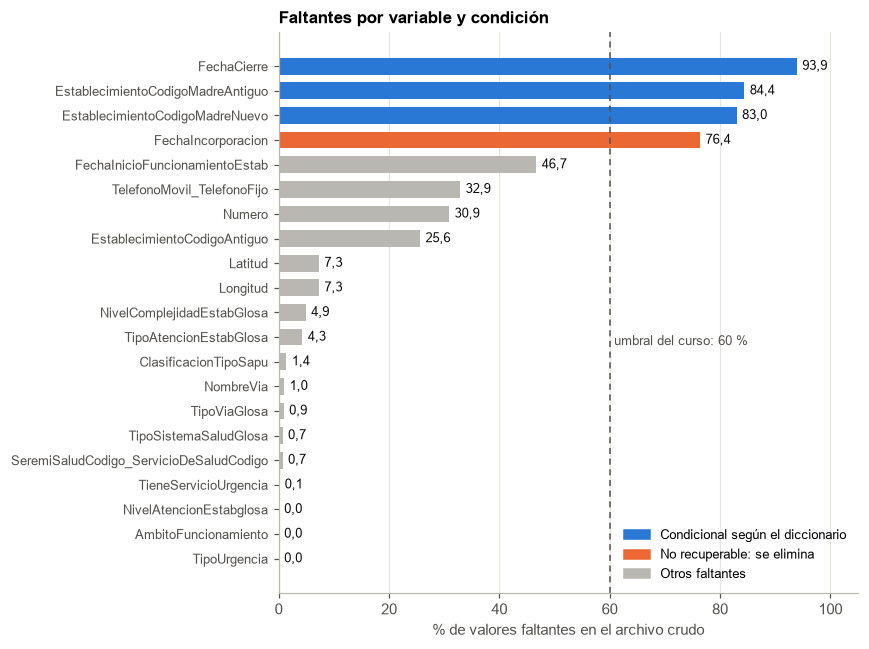

In [3]:
nulos_crudo = datos.tabla_nulos(crudo)
print("Filas y columnas:", crudo.shape, "| tipos leídos:", crudo.dtypes.astype(str).unique().tolist())
print("Filas duplicadas exactas:", int(crudo.duplicated().sum()), "| código vigente único:", crudo["EstablecimientoCodigo"].is_unique)
display(nulos_crudo[nulos_crudo["nulos"] > 0])

COL_CONDICIONALES = ["FechaCierre", "EstablecimientoCodigoMadreAntiguo", "EstablecimientoCodigoMadreNuevo"]
COL_NO_RECUPERABLES = ["FechaIncorporacion"]
figura = graficos.barras_nulos(nulos_crudo, COL_CONDICIONALES, COL_NO_RECUPERABLES)
graficos.guardar(figura, RUTAS["figuras"] / "fig1_nulos.png")
plt.show()

### 2.2 ¿De dónde vienen los faltantes?

**Por qué.** Antes de elegir un tratamiento hay que saber si el nulo es una condición declarada o una pérdida. Se cruzan los faltantes principales con el estado y con el sector. El diccionario oficial declara `FechaCierre` solo para cerrados, `FechaIncorporacion` solo para vigentes y los códigos madre solo cuando existe un establecimiento madre.

In [4]:
# Vista temporal: solo se normaliza la escritura para poder agrupar, sin afectar a crudo.
vista = crudo.copy()
vista["estado"] = vista["EstadoFuncionamiento"].str.lower().str.split(" ").str[0]
vista["sistema"] = vista["TipoSistemaSaludGlosa"].fillna("Sin dato").replace("Gendamería", "Gendarmería")

def porcentaje_nulos_por(datos_vista, columna, grupo):
    """Tabla de total, nulos y porcentaje de nulos de ``columna`` en cada ``grupo``."""
    return (datos_vista[columna].isna().groupby(datos_vista[grupo]).agg(total="size", nulos="sum")
            .assign(pct_nulos=lambda t: (100 * t["nulos"] / t["total"]).round(1)))

MECANISMOS = [("FechaCierre", "estado"), ("FechaIncorporacion", "estado"), ("Latitud", "estado"),
              ("Latitud", "sistema"), ("FechaInicioFuncionamientoEstab", "sistema")]
tablas_mecanismo = {}
for columna, grupo in MECANISMOS:
    tablas_mecanismo[f"{columna}|{grupo}"] = porcentaje_nulos_por(vista, columna, grupo)
    print(f"\n{columna} según {grupo}")
    display(tablas_mecanismo[f"{columna}|{grupo}"])

madre = pd.crosstab(crudo["EstablecimientoCodigoMadreAntiguo"].notna(), crudo["EstablecimientoCodigoMadreNuevo"].notna(),
                    rownames=["madre antiguo presente"], colnames=["madre nuevo presente"])
display(madre)
madre_valida = crudo["EstablecimientoCodigoMadreNuevo"].dropna().isin(crudo["EstablecimientoCodigo"]).mean()
print(f"Códigos madre nuevos que existen como establecimiento: {madre_valida:.1%}")

m = tablas_mecanismo
resultados["mecanismos"] = {k: v.reset_index().to_dict("records") for k, v in m.items()}
resultados["madre"] = {"solo_nuevo": int(madre.loc[False, True]), "solo_antiguo": int(madre.loc[True, False]), "ambos": int(madre.loc[True, True]),
                       "pct_valido": float(100 * madre_valida)}


FechaCierre según estado

,total,nulos,pct_nulos
estado,,,
cerrado,431,77,17.9
vigente,5406,5406,100.0



FechaIncorporacion según estado

,total,nulos,pct_nulos
estado,,,
cerrado,431,404,93.7
vigente,5406,4056,75.0



Latitud según estado

,total,nulos,pct_nulos
estado,,,
cerrado,431,347,80.5
vigente,5406,79,1.5


... (2 outputs left out)


FechaInicioFuncionamientoEstab según sistema

,total,nulos,pct_nulos
sistema,,,
Fuerzas Armadas y de Orden (FFAA),81,9,11.1
Gendarmería,34,2,5.9
No Aplica,41,39,95.1
Privado,2384,120,5.0
Público,3258,2527,77.6
Sin dato,39,26,66.7


madre nuevo presente,False,True
madre antiguo presente,,
False,4844,85
True,0,908


Códigos madre nuevos que existen como establecimiento: 100.0%

**Lectura de la tabla.** Los nulos de `FechaCierre` son estructurales en vigentes: ningún vigente registra fecha. Sí hay una pérdida real en un grupo menor, los cerrados sin fecha. Las coordenadas se concentran de forma aplastante en los cerrados, por lo que no faltan al azar. La fecha de inicio falta sobre todo en el sector público.

### 2.3 Categorías, pseudonulos y consistencia de códigos

**Por qué.** Una misma categoría escrita de dos maneras se contaría como dos. El detector compara los valores sin mayúsculas, tildes ni signos; los errores ortográficos, como `Gendamería`, y los valores truncados no se detectan así, por lo que se revisaron en las tablas de frecuencia y se declaran a mano en `MAPEOS_CATEGORIAS`.

In [5]:
categoricas = [c for c in crudo.columns if crudo[c].nunique() <= 50]
variantes = limpieza.detectar_variantes(crudo, categoricas)
pseudonulos = limpieza.detectar_pseudonulos(crudo)
print("Variantes por mayúsculas o tildes:")
display(variantes)
print("Pseudonulos escritos como texto:", len(pseudonulos))

for columna in ["TieneServicioUrgencia", "EstadoFuncionamiento", "TipoAtencionEstabGlosa", "NivelComplejidadEstabGlosa",
                "NivelAtencionEstabglosa", "TipoSistemaSaludGlosa", "Certificacion"]:
    print(f"\n{columna}:", crudo[columna].value_counts(dropna=False).to_dict())

prefijo_ok = (crudo["ComunaCodigo"].str[:2] == crudo["RegionCodigo"]).all()
codigo_glosa = crudo.groupby("ComunaCodigo")["ComunaGlosa"].nunique().max()
# Un mismo código numérico puede ser un Servicio de Salud y una SEREMI distintos.
ambiguos = crudo.groupby("SeremiSaludCodigo_ServicioDeSaludCodigo")["SeremiSaludGlosa_ServicioDeSaludGlosa"].nunique().gt(1).sum()
print(f"\nComuna coherente con región: {prefijo_ok} | glosas por código de comuna: {codigo_glosa} | códigos SEREMI/Servicio ambiguos: {ambiguos}")
resultados["categorias"] = {"variantes_detectadas": len(variantes), "pseudonulos": len(pseudonulos), "codigos_seremi_ambiguos": int(ambiguos),
                            "prefijo_comuna_ok": bool(prefijo_ok)}

Variantes por mayúsculas o tildes:

,variable,variantes,conteos
0,TipoPertenenciaEstabGlosa,No Perteneciente al Sistema Nacional de Servicios de Salud | No pertenecient...,2367 | 141
1,TieneServicioUrgencia,NO | No,4794 | 14
2,EstadoFuncionamiento,Vigente en Operación Habitual | Vigente en operación habitual,5271 | 135


Pseudonulos escritos como texto:

0


TieneServicioUrgencia:

{'NO': 4794, 'SI': 827, 'No Aplica': 194, 'No': 14, nan: 8}

... (9 outputs left out)

{'Público': 3258, 'Privado': 2384, 'Fuerzas Armadas y de Orden (FFAA)': 81, 'No Aplica': 41, nan: 39, 'Gendamería': 34}


Certificacion:

{'No Aplica': 5156, 'Centro de Salud Familiar': 606, 'Autogestionado en Red (EAR)': 62, 'Invitados a ser EAR': 12, 'Candidato a ser EAR': 1}


Comuna coherente con región: True | glosas por código de comuna: 1 | códigos SEREMI/Servicio ambiguos: 16

### 2.4 Fechas

**Por qué.** Una fecha válida en formato puede ser imposible o sospechosa. Se mide cuántas superan el corte del archivo, cuántas contradicen la fecha de cierre y si alguna se repite de un modo incompatible con una fecha real.

In [6]:
fechas_vista, tabla_fechas = limpieza.convertir_fechas(crudo)
display(tabla_fechas)
inicio = fechas_vista["FechaInicioFuncionamientoEstab"]
corte = pd.to_datetime(entorno.FECHA_CORTE, dayfirst=True)
frecuentes = inicio.value_counts().head(5)
print("Fechas de inicio más repetidas:")
display(frecuentes.to_frame("repeticiones"))
FECHA_ATIPICA = frecuentes.index[0]
pct_atipica = 100 * frecuentes.iloc[0] / inicio.notna().sum()
print(f"La fecha {FECHA_ATIPICA:%d-%m-%Y} concentra {pct_atipica:.1f} % de las fechas observadas; la siguiente solo repite {frecuentes.iloc[1]} veces.")
print("Sector de los registros con esa fecha:")
print(vista.loc[inicio.eq(FECHA_ATIPICA), "sistema"].value_counts().to_string())
futuras_inicio = int((inicio > corte).sum())
futuras_incorp = int((fechas_vista["FechaIncorporacion"] > corte).sum())
print(f"\nInicio posterior al corte: {futuras_inicio} | Incorporación posterior al corte: {futuras_incorp} | Inicio posterior al cierre: {int((inicio > fechas_vista['FechaCierre']).sum())}")
resultados["fechas"] = {"fecha_atipica": f"{FECHA_ATIPICA:%d-%m-%Y}", "repeticiones": int(frecuentes.iloc[0]), "siguiente": int(frecuentes.iloc[1]),
                        "pct_observadas": float(pct_atipica), "observadas": int(inicio.notna().sum()), "futuras_inicio": futuras_inicio,
                        "futuras_incorporacion": futuras_incorp,
                        "atipica_por_sistema": vista.loc[inicio.eq(FECHA_ATIPICA), "sistema"].value_counts().to_dict()}

,variable,con_valor,no_convertidas,minima,maxima
0,FechaInicioFuncionamientoEstab,3114,0,01-01-1925,15-12-2026
1,FechaIncorporacion,1377,0,02-08-2006,08-12-2026
2,FechaCierre,354,0,01-01-2007,03-11-2026


Fechas de inicio más repetidas:

,repeticiones
FechaInicioFuncionamientoEstab,
2009-01-01,760
2021-01-29,28
2005-12-30,22
2004-01-01,18
2010-01-03,13


La fecha 01-01-2009 concentra 24.4 % de las fechas observadas; la siguiente solo repite 28 veces.

Sector de los registros con esa fecha:

sistema
Privado                              648
Fuerzas Armadas y de Orden (FFAA)     50
Público                               43
Gendarmería                           16
No Aplica                              2
Sin dato                               1


Inicio posterior al corte: 5 | Incorporación posterior al corte: 5 | Inicio posterior al cierre: 1

### 2.5 Atípicos en las únicas numéricas reales

**Qué se mide.** Primero el criterio del rango intercuartílico sobre `Latitud` y `Longitud`. Después una comprobación de dominio, la distancia de cada punto a la mediana de su comuna, porque un valor puede ser atípico sin ser erróneo y viceversa. Isla de Pascua es un extremo real; una clínica de Iquique ubicada a la latitud de Valdivia no lo es.

No convertidos a número:

{'Latitud': 0, 'Longitud': 0}

,variable,n,media,mediana,desv_est,asimetria,lim_inf,lim_sup,atipicos,pct_atipicos,min,max
0,Latitud,5411,-34.402,-33.977,5.615,0.386,-44.454,-25.988,532,9.832,-54.935,-17.595
1,Longitud,5411,-71.565,-71.296,1.179,-6.344,-75.045,-68.082,9,0.166,-109.421,-67.600


,EstablecimientoGlosa,ComunaGlosa,RegionGlosa,Latitud,Longitud,km_a_mediana
12,Clínica Dental Móvil Simple. Pat. RW6740 (Iquique),Iquique,Tarapacá,-39.813792,-73.240135,2198.3
5032,Clinica Red Medical,La Serena,Coquimbo,-23.654793,-70.402053,701.1
5372,Clínica Dental Ultradent Ovalle,Ovalle,Coquimbo,-36.600952,-72.089455,672.2
3190,Clínica Los Maitenes,Melipilla,Metropolitana de Santiago,-39.295060,-72.211826,630.0
1452,Posta de Salud Rural Puerto Edén,Natales,Magallanes y de la Antártica Chilena,-49.125490,-74.412710,319.8
4810,Policlinico Mantos de Oro La Coipa,Copiapó,Atacama,-26.828425,-69.263703,121.3
4768,Policlinico Campamento Minera Maricunga,Copiapó,Atacama,-27.545725,-69.282408,105.2
4756,Policlínico Plataforma Este Caserones,Tierra Amarilla,Atacama,-28.180895,-69.533515,102.3


Coordenadas a más de 400 km de su comuna: 4

Regla relativa por comuna: 11 puntos para revisar; 4 coinciden con el umbral absoluto

,EstablecimientoGlosa,ComunaGlosa,TipoEstablecimientoGlosa,km_a_mediana
12,Clínica Dental Móvil Simple. Pat. RW6740 (Iquique),Iquique,Unidad de Procedimientos Móvil,2198.3
5032,Clinica Red Medical,La Serena,Centro de Salud Privado,701.1
5372,Clínica Dental Ultradent Ovalle,Ovalle,Clínica Dental,672.2
3190,Clínica Los Maitenes,Melipilla,Clínica,630.0
4810,Policlinico Mantos de Oro La Coipa,Copiapó,Otro,121.3
4768,Policlinico Campamento Minera Maricunga,Copiapó,Otro,105.2
4408,Posta de Salud Rural San Marcos,Iquique,Posta de Salud Rural (PSR),99.1
4401,Posta de Salud Rural Caspana,Calama,Posta de Salud Rural (PSR),74.7
4402,Posta de Salud Rural Ayquina,Calama,Posta de Salud Rural (PSR),65.3
36,SUR Chanavayita,Iquique,Servicio de Urgencia Rural (SUR),53.5


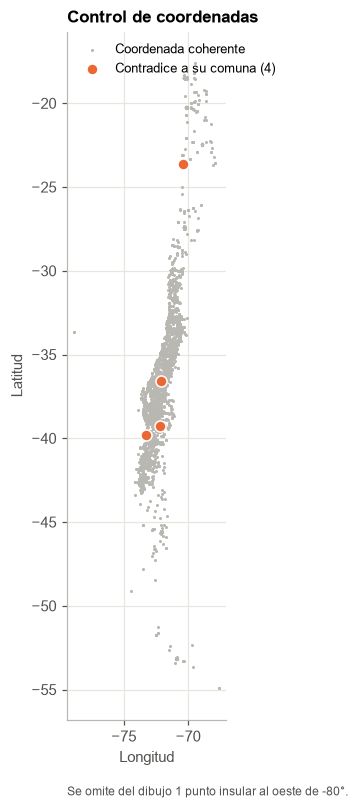

In [7]:
vista_num, no_convertidos = limpieza.convertir_numericas(crudo, ["Latitud", "Longitud"])
print("No convertidos a número:", no_convertidos)
tabla_atipicos = limpieza.resumen_atipicos(vista_num, ["Latitud", "Longitud"])
display(tabla_atipicos.round(3))

km_comuna = limpieza.distancia_a_mediana_comunal(vista_num)
mayores = (vista_num.assign(km_a_mediana=km_comuna.round(1))
           .sort_values("km_a_mediana", ascending=False)[["EstablecimientoGlosa", "ComunaGlosa", "RegionGlosa", "Latitud", "Longitud", "km_a_mediana"]].head(8))
display(mayores)
UMBRAL_KM = 400  # hay un salto entre el cuarto y el quinto valor, y el quinto es una localidad real (Puerto Edén, comuna de Natales)
errores_coordenadas = km_comuna > UMBRAL_KM
print(f"Coordenadas a más de {UMBRAL_KM} km de su comuna: {int(errores_coordenadas.sum())}")
# Regla relativa: se usa para revisar, porque un campamento remoto puede cumplirla y ser real.
relativas = limpieza.marcar_coordenadas_relativas(vista_num)
tabla_relativas = (vista_num.assign(km_a_mediana=km_comuna.round(1))[relativas]
                   .sort_values("km_a_mediana", ascending=False)[["EstablecimientoGlosa", "ComunaGlosa", "TipoEstablecimientoGlosa", "km_a_mediana"]])
print(f"Regla relativa por comuna: {int(relativas.sum())} puntos para revisar; {int((relativas & errores_coordenadas).sum())} coinciden con el umbral absoluto")
display(tabla_relativas.head(12))
resultados["relativas"] = {"marcadas": int(relativas.sum()), "coinciden": int((relativas & errores_coordenadas).sum()),
                           "tabla": tabla_relativas.to_dict("records")}
resultados["atipicos"] = {"tabla": tabla_atipicos.to_dict("records"), "umbral_km": UMBRAL_KM, "errores": int(errores_coordenadas.sum()),
                          "cuarto_km": float(mayores["km_a_mediana"].iloc[3]), "quinto_km": float(mayores["km_a_mediana"].iloc[4]),
                          "mayor_km": float(mayores["km_a_mediana"].iloc[0])}
figura = graficos.mapa_control_coordenadas(vista_num, errores_coordenadas)
graficos.guardar(figura, RUTAS["figuras"] / "fig2_coordenadas.png")
plt.show()

**Lectura.** El criterio IQR marca muchos puntos que son simplemente el norte y el sur de un país largo: no se eliminan. En cambio, cuatro coordenadas contradicen a su comuna por más de 600 km. Se corrigen en la limpieza. El umbral de 400 km se apoya en un salto observado, no en un valor habitual: el quinto mayor, Puerto Edén, es una localidad remota real de su comuna.

### 2.6 Registros posiblemente duplicados

No hay duplicados exactos y el código es único, pero se revisa si un mismo establecimiento pudo registrarse con dos códigos.

In [8]:
claves_duplicado = ["EstablecimientoGlosa", "ComunaCodigo", "NombreVia", "Numero"]
normal_vista = crudo.copy()
for columna in claves_duplicado:
    normal_vista[columna] = limpieza.normalizar_texto(normal_vista[columna])
posibles = limpieza.marcar_posibles_duplicados(normal_vista, claves_duplicado)
display(normal_vista.loc[posibles, ["EstablecimientoCodigo", *claves_duplicado, "EstadoFuncionamiento"]].sort_values("EstablecimientoGlosa").head(8))
print("Registros con igual nombre, comuna y dirección:", int(posibles.sum()))
resultados["duplicados"] = {"exactos": int(crudo.duplicated().sum()), "posibles": int(posibles.sum())}

,EstablecimientoCodigo,EstablecimientoGlosa,ComunaCodigo,NombreVia,Numero,EstadoFuncionamiento
4727,201331,Centro Médico Andes Salud Ancud,10202,Costanera,750,Vigente en Operación Habitual
5642,202300,Centro Médico Andes Salud Ancud,10202,Costanera,750,Vigente en Operación Habitual
4944,201576,Centro Médico Andes Salud Talca,07101,4 Norte,1656,Vigente en Operación Habitual
5053,201691,Centro Médico Andes Salud Talca,07101,4 Norte,1656,Vigente en Operación Habitual
1332,200469,Clínica Vida Estética,13123,Eliodoro Yáñez,1759,Cerrado
4804,201426,Clínica Vida Estética,13123,Eliodoro Yáñez,1759,Vigente en Operación Habitual
1142,111268,Clínica del Trabajador AChS,13501,Merced,710,Cerrado
3189,110268,Clínica del Trabajador AChS,13501,Merced,710,Vigente en Operación Habitual


Registros con igual nombre, comuna y dirección:

16

### 2.7 Qué representa una fila y cómo se cargó el registro

**Por qué.** La unidad de observación no es homogénea: junto a establecimientos hay unidades, programas y dispositivos móviles. Además, algunos patrones sugieren vías de carga distintas. El conjunto no incluye el historial de carga, por lo que todo lo que sigue es **indicio y no confirmación**.

In [9]:
filas_registro = auditoria.composicion_filas(crudo)
print("Composición de las filas:", filas_registro)

patron = auditoria.patron_incorporacion(crudo)
display(patron["tabla"].round(1))
print("FechaIncorporacion por año:", patron["por_anio"])
print(f"Valores desde 2022: {patron['pct_desde_2022']:.1f} %")

variante = auditoria.perfil_variante_estado(crudo)
display(pd.Series(variante, name="valor").to_frame())

discrepancias = auditoria.discrepancias_diccionario(crudo)
display(discrepancias)
resultados["auditoria"] = {"filas": filas_registro, "incorporacion": {"tabla": patron["tabla"].reset_index().to_dict("records"),
                           "por_anio": patron["por_anio"], "pct_desde_2022": patron["pct_desde_2022"]},
                           "variante": variante, "discrepancias": discrepancias.to_dict("records")}

Composición de las filas:

{'establecimientos': 5371, 'unidades': 395, 'programas': 29, 'ambito_no_aplica': 41, 'moviles': 57}

,registros,con_fecha,pct_con_fecha
EstablecimientoCodigo,,,
"(0, 130000]",3264,49,1.5
"(130000, 200000]",120,0,0.0
"(200000, 201000]",999,50,5.0
"(201000, 202000]",964,835,86.6
"(202000, 203000]",490,443,90.4


FechaIncorporacion por año:

{2006: 1, 2020: 1, 2021: 23, 2022: 162, 2023: 177, 2024: 334, 2025: 450, 2026: 229}

Valores desde 2022: 98.2 %

,valor
filas,135
codigo_min,201824
codigo_max,202253
pct_con_incorporacion,100.0
pct_con_incorporacion_otros,23.050655
decimales_mediana,8.0
decimales_mediana_otros,6.0
anio_incorporacion,"{'2025': 129, '2026': 5, '2024': 1}"
no_minuscula_en_variante,13
no_minuscula_total,14


,variable,solo_en_diccionario,solo_en_archivo,filas_con_valor_no_declarado
0,EstadoFuncionamiento,Cerrado Definitivo; Cerrado Temporal; Vigente en operación transitoria,Cerrado; Vigente en Operación Habitual,5702
1,NivelAtencionEstabglosa,Primario; Secundario; Terciario,Primer Nivel; Segundo Nivel; Tercer Nivel,4523
2,NivelComplejidadEstabGlosa,—,—,0
3,TipoAtencionEstabGlosa,Atención Abierta- Ambulatoria; Atención Cerrada- Hospitalaria,Atención Abierta-Ambu; Atención Abierta-Ambulatoria; Atención Cerrada-Hospit...,5531
4,TieneServicioUrgencia,—,No,14
5,ClasificacionTipoSapu,Avanzando; No aplica; Pendiente,Avanzado; No Aplica,5510
6,AmbitoFuncionamiento,—,No Aplica,41
7,TipoSistemaSaludGlosa,Fuerzas Armadas y de Orden y Seguridad; Gendarmería,Fuerzas Armadas y de Orden (FFAA); Gendamería; No Aplica,156
8,Certificacion,Certificado como CESFAM; Invitado a ser EAR; No Certificado como CESFAM; Pen...,Centro de Salud Familiar; Invitados a ser EAR,618
9,TipoUrgencia,Ambulatoria (SAPU); Ambulatoria (SAR); Ambulatoria (SUR); Ambulatoria Privad...,Otro; SAPU Dental; Urgencia Ambulatoria (SAPU); Urgencia Ambulatoria (SAR); ...,820


**Lectura.** `FechaIncorporacion` se concentra en los códigos correlativos más altos y en años recientes: es un indicio de que el campo se empezó a llenar en una época del registro, no de que falte al azar. La variante «Vigente en operación habitual» aparece solo en un tramo de códigos altos, siempre con fecha de incorporación y con otras escrituras propias: sugiere otra vía de carga, sin que se pueda confirmar. El archivo solo trae «Cerrado», mientras el diccionario distingue cierre temporal y definitivo, de modo que no se pueden separar. La tabla registra además otras diferencias entre el diccionario y el archivo; también se observó en el diccionario oficial que las definiciones de latitud y longitud están intercambiadas.

## 3. Limpieza

**Lógica del bloque.** Se avanza de lo más seguro a lo más discutible: primero la escritura, después los tipos, luego las anomalías, los faltantes explicados por el diccionario y, al final, la imputación. Cada función devuelve una copia y sus conteos, de modo que el flujo se puede verificar paso a paso.

### 3.1 Texto y categorías

In [10]:
trabajo = crudo.copy()   # todo cambio ocurre sobre esta copia

espacios = {}
for columna in trabajo.columns:
    normalizada = limpieza.normalizar_texto(trabajo[columna])
    cambios = int((normalizada.fillna("") != trabajo[columna].fillna("")).sum())
    if cambios:
        espacios[columna] = cambios
    trabajo[columna] = normalizada
print("Valores con espacios corregidos:", espacios)

trabajo, tabla_mapeos = limpieza.aplicar_mapeos(trabajo)
display(tabla_mapeos)
quedan = limpieza.detectar_variantes(trabajo, categoricas)
assert quedan.empty, "Quedan variantes sin unificar."
print("[OK] Sin variantes pendientes tras la corrección.")
print("Categorías de EstadoFuncionamiento:", trabajo["EstadoFuncionamiento"].value_counts().to_dict())

filas_mapeadas = int(tabla_mapeos["filas"].sum())
resultados["texto"] = {"espacios": espacios, "espacios_total": int(sum(espacios.values())), "filas_mapeadas": filas_mapeadas,
                       "mapeos": tabla_mapeos.to_dict("records")}
bitacora.registrar("limpieza", "Unificar variantes y corregir escritura con un mapeo declarado",
                   "La misma categoría escrita de dos maneras se contaría como dos, y la moda por grupo quedaría sesgada",
                   f"{filas_mapeadas} valores unificados en {len(tabla_mapeos)} reglas; {sum(espacios.values())} valores con espacios corregidos; 0 variantes restantes",
                   "Corrección automática por similitud de texto: podría fundir categorías distintas")

Valores con espacios corregidos:

{'SeremiSaludGlosa_ServicioDeSaludGlosa': 152, 'TipoEstablecimientoGlosa': 233, 'EstablecimientoGlosa': 71, 'NombreVia': 83, 'TelefonoMovil_TelefonoFijo': 12}

,variable,original,canonico,filas
0,TipoPertenenciaEstabGlosa,No perteneciente al Sistema Nacional de Servicios de Salud,No Perteneciente al Sistema Nacional de Servicios de Salud,141
1,TieneServicioUrgencia,No,NO,14
2,EstadoFuncionamiento,Vigente en operación habitual,Vigente en Operación Habitual,135
3,TipoAtencionEstabGlosa,Atención Abierta-Ambu,Atención Abierta-Ambulatoria,1
4,DependenciaAdministrativa,Gendamería,Gendarmería,34
5,TipoSistemaSaludGlosa,Gendamería,Gendarmería,34
6,TipoEstablecimientoGlosa,Centro Terapeútico,Centro Terapéutico,19
7,TipoUrgencia,Urgencia ambulatoria privada,Urgencia Ambulatoria Privada,2


[OK] Sin variantes pendientes tras la corrección.

Categorías de EstadoFuncionamiento:

{'Vigente en Operación Habitual': 5406, 'Cerrado': 431}

### 3.2 Tipos (*casting*)

Se convierten las fechas con el formato declarado por el diccionario y las coordenadas a `float`. Los códigos siguen como texto: son etiquetas, no cantidades. Tampoco se calcula con ellos.

In [11]:
trabajo, tabla_fechas_cast = limpieza.convertir_fechas(trabajo)
trabajo, no_convertidos = limpieza.convertir_numericas(trabajo, ["Latitud", "Longitud"])
display(tabla_fechas_cast)
print("Coordenadas no convertidas:", no_convertidos)
assert tabla_fechas_cast["no_convertidas"].sum() == 0 and sum(no_convertidos.values()) == 0, "Hubo valores que no se pudieron convertir."
print(trabajo[["Latitud", "Longitud", "FechaCierre"]].dtypes.to_string())
bitacora.registrar("limpieza", "Convertir fechas con formato explícito dd-mm-aaaa y coordenadas a float; mantener códigos como texto",
                   "Un formato explícito impide intercambiar día y mes; operar con un código no tiene significado",
                   f"{fmt(int(tabla_fechas_cast['con_valor'].sum()),0)} fechas y {fmt(int(trabajo['Latitud'].notna().sum()),0)} pares de coordenadas convertidos, con 0 fallas",
                   "Inferencia automática del formato de fecha")

,variable,con_valor,no_convertidas,minima,maxima
0,FechaInicioFuncionamientoEstab,3114,0,01-01-1925,15-12-2026
1,FechaIncorporacion,1377,0,02-08-2006,08-12-2026
2,FechaCierre,354,0,01-01-2007,03-11-2026


Coordenadas no convertidas:

{'Latitud': 0, 'Longitud': 0}

Latitud               float64
Longitud              float64
FechaCierre    datetime64[us]

### 3.3 Anomalías: coordenadas contradictorias y fechas imposibles

**Decisión.** Las coordenadas a más de 400 km de su comuna pasan a faltantes: su valor registrado es falso, así que se tratan igual que un dato ausente. Las fechas de inicio posteriores al corte o al cierre también se anulan. No se corrigen porque no hay forma de saber cuál sería el valor correcto.

In [12]:
registros_erroneos = trabajo.loc[errores_coordenadas, ["EstablecimientoCodigo", "EstablecimientoGlosa", "ComunaGlosa", "Latitud", "Longitud", "EstadoFuncionamiento"]]
display(registros_erroneos)
trabajo, mascara_errores = limpieza.anular_coordenadas_erroneas(trabajo, UMBRAL_KM)
assert mascara_errores.equals(errores_coordenadas), "La detección no coincide con la exploración."
trabajo, conteo_fechas = limpieza.depurar_fechas(trabajo, entorno.FECHA_CORTE)
print("Coordenadas anuladas:", int(mascara_errores.sum()), "| fechas de inicio anuladas:", conteo_fechas)

resultados["anomalias"] = {"coordenadas_anuladas": int(mascara_errores.sum()),
                           "coordenadas_vigentes": int(registros_erroneos["EstadoFuncionamiento"].str.startswith("Vigente").sum()), **conteo_fechas}
bitacora.registrar("limpieza", f"Anular {int(mascara_errores.sum())} coordenadas a más de {UMBRAL_KM} km de su comuna",
                   "El valor registrado es incompatible con la comuna declarada; mantenerlo falsearía la distancia a urgencia",
                   f"Distancias detectadas entre {fmt(resultados['atipicos']['cuarto_km'],0)} y {fmt(resultados['atipicos']['mayor_km'],0)} km; el siguiente valor, {fmt(resultados['atipicos']['quinto_km'],0)} km, es una localidad real y se conserva",
                   "Criterio IQR: marca el norte y el sur del país y a Isla de Pascua, que son valores reales")
bitacora.registrar("limpieza", "Anular fechas de inicio posteriores al corte o al cierre",
                   "Son imposibles; se ignora cuál es el dato correcto, por lo que no se reemplazan",
                   f"{conteo_fechas['inicio_posterior_al_corte']} posteriores al corte y {conteo_fechas['inicio_posterior_al_cierre']} posterior al cierre",
                   "Recortar la fecha al corte: inventaría un valor")

,EstablecimientoCodigo,EstablecimientoGlosa,ComunaGlosa,Latitud,Longitud,EstadoFuncionamiento
12,102012,Clínica Dental Móvil Simple. Pat. RW6740 (Iquique),Iquique,-39.813792,-73.240135,Cerrado
3190,110270,Clínica Los Maitenes,Melipilla,-39.295060,-72.211826,Vigente en Operación Habitual
5032,201669,Clinica Red Medical,La Serena,-23.654793,-70.402053,Vigente en Operación Habitual
5372,202018,Clínica Dental Ultradent Ovalle,Ovalle,-36.600952,-72.089455,Vigente en Operación Habitual


Coordenadas anuladas:

4

| fechas de inicio anuladas:

{'inicio_posterior_al_corte': 5, 'inicio_posterior_al_cierre': 1}

### 3.4 Faltantes explicados por el diccionario

**Por qué antes que imputar.** Lo que la norma declara como no aplicable no es un dato perdido. El diccionario excluye a los laboratorios de complejidad y tipo de atención, y limita la clasificación SAPU a los servicios SAPU. Para la urgencia hay una regla determinista: `TipoUrgencia` indica directamente si el establecimiento tiene o no servicio.

In [13]:
es_laboratorio = trabajo["TipoEstablecimientoGlosa"].eq("Laboratorio Clínico")
es_sapu = trabajo["TipoUrgencia"].eq("Urgencia Ambulatoria (SAPU)")
estructurales = {}
reglas = [("NivelComplejidadEstabGlosa", es_laboratorio, "No Aplica"),
          ("TipoAtencionEstabGlosa", es_laboratorio, "No Aplica"),
          ("ClasificacionTipoSapu", ~es_sapu, "No Aplica"),
          ("TieneServicioUrgencia", trabajo["TipoUrgencia"].eq("No Aplica"), "NO"),
          ("TieneServicioUrgencia", trabajo["TipoUrgencia"].notna() & trabajo["TipoUrgencia"].ne("No Aplica"), "SI")]
for columna, condicion, valor in reglas:   # el bucle evita repetir el mismo bloque por columna
    trabajo, n = limpieza.completar_por_condicion(trabajo, columna, condicion, valor)
    estructurales[f"{columna} -> {valor}"] = n
print("Faltantes resueltos por regla:", estructurales)
resultados["estructurales"] = estructurales
bitacora.registrar("limpieza", "Asignar No Aplica o el valor determinista cuando el diccionario o TipoUrgencia lo establecen",
                   "Estos nulos no son información perdida: son condiciones declaradas, y tratarlos como faltantes los mezclaría con los reales",
                   "; ".join(f"{k}: {v}" for k, v in estructurales.items()),
                   "Imputar la moda global a todos los nulos")

Faltantes resueltos por regla:

{'NivelComplejidadEstabGlosa -> No Aplica': 66, 'TipoAtencionEstabGlosa -> No Aplica': 65, 'ClasificacionTipoSapu -> No Aplica': 57, 'TieneServicioUrgencia -> NO': 6, 'TieneServicioUrgencia -> SI': 1}

### 3.5 Variables categóricas restantes: comparar antes de imputar

**Qué se compara.** Se ocultan valores conocidos (10 %, semilla 42) y se mide el acierto de tres alternativas: la moda global, la moda por tipo de establecimiento y la moda por tipo solo cuando el grupo es casi homogéneo, con pureza de al menos 95 %.

**Criterio.** Una imputación errada contamina sin dejar rastro, así que se prefiere la que acierta más aunque cubra menos. Lo que queda sin cubrir se etiqueta `Sin dato`: es preferible declarar que no se sabe. Para `TipoSistemaSaludGlosa` el agrupador es la dependencia administrativa, que determina el sector casi por completo.

In [14]:
OBJETIVOS_CATEGORICOS = [("NivelComplejidadEstabGlosa", "TipoEstablecimientoGlosa"), ("TipoAtencionEstabGlosa", "TipoEstablecimientoGlosa"),
                         ("NivelAtencionEstabglosa", "TipoEstablecimientoGlosa"), ("AmbitoFuncionamiento", "TipoEstablecimientoGlosa"),
                         ("TipoSistemaSaludGlosa", "DependenciaAdministrativa"), ("TieneServicioUrgencia", "TipoEstablecimientoGlosa"),
                         ("TipoUrgencia", "TipoEstablecimientoGlosa"), ("ClasificacionTipoSapu", "TipoEstablecimientoGlosa")]
evaluaciones, conteos_categoricos = [], {}
for columna, grupo in OBJETIVOS_CATEGORICOS:
    nulos_antes = int(trabajo[columna].isna().sum())
    evaluacion = limpieza.evaluar_imputacion_categorica(trabajo, columna, grupo, semilla=entorno.SEMILLA).assign(variable=columna, nulos=nulos_antes)
    evaluaciones.append(evaluacion)
tabla_evaluacion = pd.concat(evaluaciones, ignore_index=True)[["variable", "nulos", "metodo", "ocultos", "cobertura_pct", "acierto_sobre_cubiertos_pct"]]
display(tabla_evaluacion)

for columna, grupo in OBJETIVOS_CATEGORICOS:
    nulos_antes = int(trabajo[columna].isna().sum())
    trabajo, conteo = limpieza.imputar_categorica_por_grupo(trabajo, columna, grupo)
    conteos_categoricos[columna] = {"nulos": nulos_antes, **conteo}
tabla_categoricas = pd.DataFrame(conteos_categoricos).T
display(tabla_categoricas)
assert trabajo[[c for c, _ in OBJETIVOS_CATEGORICOS]].notna().all().all()
sin_dato_urgencia = trabajo.loc[trabajo["TieneServicioUrgencia"].eq("Sin dato"), ["EstablecimientoGlosa", "TipoEstablecimientoGlosa", "EstadoFuncionamiento"]]
print("Registro sin dato de urgencia; no se usará como referencia:")
display(sin_dato_urgencia)
resultados["categoricas_imputacion"] = {"evaluacion": tabla_evaluacion.to_dict("records"), "conteos": conteos_categoricos,
                                        "sin_dato_urgencia": sin_dato_urgencia["EstablecimientoGlosa"].tolist()}

comp = tabla_evaluacion[tabla_evaluacion["variable"].eq("NivelComplejidadEstabGlosa")].set_index("metodo")
n_pureza = [m for m in comp.index if "pureza" in m][0]
bitacora.registrar("limpieza", "Imputar categorías con la moda del grupo solo si la pureza es de al menos 95 %; el resto queda como Sin dato",
                   "Una categoría falsa no deja rastro y sesgaría los recuentos por nivel; declarar que no se sabe es más honesto",
                   f"En complejidad, acierto de {fmt(comp.loc['moda global','acierto_sobre_cubiertos_pct'])} % con moda global y {fmt(comp.loc[n_pureza,'acierto_sobre_cubiertos_pct'])} % con la regla elegida, cubriendo {fmt(comp.loc[n_pureza,'cobertura_pct'])} %; imputados {conteos_categoricos['NivelComplejidadEstabGlosa']['imputados_moda_grupo']} y Sin dato {conteos_categoricos['NivelComplejidadEstabGlosa']['etiquetados_sin_dato']}",
                   "Moda global: cubre todo, pero con menor acierto")

,variable,nulos,metodo,ocultos,cobertura_pct,acierto_sobre_cubiertos_pct
0,NivelComplejidadEstabGlosa,222,moda global,561,100.0,60.1
1,NivelComplejidadEstabGlosa,222,moda por grupo,561,100.0,88.8
2,NivelComplejidadEstabGlosa,222,moda por grupo con pureza >= 95%,561,63.5,99.4
3,TipoAtencionEstabGlosa,185,moda global,565,100.0,91.3
4,TipoAtencionEstabGlosa,185,moda por grupo,565,100.0,97.3
5,TipoAtencionEstabGlosa,185,moda por grupo con pureza >= 95%,565,86.7,99.8
6,NivelAtencionEstabglosa,2,moda global,583,100.0,49.7
7,NivelAtencionEstabglosa,2,moda por grupo,583,100.0,93.0
8,NivelAtencionEstabglosa,2,moda por grupo con pureza >= 95%,583,88.7,99.6
9,AmbitoFuncionamiento,1,moda global,583,100.0,93.0


,nulos,imputados_moda_grupo,etiquetados_sin_dato
NivelComplejidadEstabGlosa,222,92,130
TipoAtencionEstabGlosa,185,127,58
NivelAtencionEstabglosa,2,2,0
AmbitoFuncionamiento,1,1,0
TipoSistemaSaludGlosa,39,24,15
TieneServicioUrgencia,1,0,1
TipoUrgencia,1,0,1
ClasificacionTipoSapu,24,0,24


Registro sin dato de urgencia; no se usará como referencia:

,EstablecimientoGlosa,TipoEstablecimientoGlosa,EstadoFuncionamiento
1534,Hospital de Chaitén,Hospital,Vigente en Operación Habitual


### 3.6 Población de análisis y faltantes de coordenadas

**Delimitación.** La pregunta es sobre la oferta vigente. La exploración mostró que las coordenadas faltan sobre todo en cerrados, y esos registros no entran al cálculo de distancia. Por eso se compara e imputa **solo en vigentes**; en los cerrados el faltante se mantiene, declarado.

**Qué se compara.** Eliminar filas, media, mediana y mediana por comuna, con dos métricas: el efecto en la desviación estándar y el error geográfico al ocultar coordenadas conocidas (10 %, semilla 42).

In [15]:
trabajo["vigente"] = trabajo["EstadoFuncionamiento"].str.startswith("Vigente").astype(int)
vigentes = trabajo[trabajo["vigente"].eq(1)].copy()
faltan_vig, faltan_cer = int(vigentes["Latitud"].isna().sum()), int(trabajo.loc[trabajo["vigente"].eq(0), "Latitud"].isna().sum())
print(f"Vigentes: {len(vigentes)} | cerrados: {int(trabajo['vigente'].eq(0).sum())}")
print(f"Coordenadas faltantes: {faltan_vig} en vigentes ({100*faltan_vig/len(vigentes):.1f} %) y {faltan_cer} en cerrados ({100*faltan_cer/int(trabajo['vigente'].eq(0).sum()):.1f} %)")

comparaciones = {c: imputacion.comparar_imputaciones(vigentes[c], vigentes["ComunaCodigo"]) for c in ["Latitud", "Longitud"]}
for columna, tabla in comparaciones.items():
    print(f"\n{columna}")
    display(tabla.round(3))
error_km = imputacion.error_oculto_coordenadas(vigentes, "ComunaCodigo", semilla=entorno.SEMILLA)
print("Error geográfico sobre coordenadas ocultas")
display(error_km.round(2))

Vigentes: 5406 | cerrados: 431

Coordenadas faltantes: 82 en vigentes (1.5 %) y 348 en cerrados (80.7 %)


Latitud

,metodo,n,filas_perdidas,media,mediana,desv_est,cambio_desv_pct
0,eliminar filas,5324,82,-34.417,-34.002,5.607,0.000
1,media,5406,0,-34.417,-34.166,5.564,-0.761
2,mediana,5406,0,-34.411,-34.002,5.564,-0.757
3,mediana por grupo,5406,0,-34.391,-33.898,5.595,-0.219



Longitud

,metodo,n,filas_perdidas,media,mediana,desv_est,cambio_desv_pct
0,eliminar filas,5324,82,-71.565,-71.293,1.182,0.000
1,media,5406,0,-71.565,-71.336,1.173,-0.761
2,mediana,5406,0,-71.560,-71.293,1.173,-0.722
3,mediana por grupo,5406,0,-71.561,-71.284,1.176,-0.488


Error geográfico sobre coordenadas ocultas

,metodo,ocultos,error_medio_km,error_mediano_km
0,media,532,453.38,307.41
1,mediana,532,452.55,351.20
2,mediana por comuna,532,10.16,2.06


**El ocultamiento al azar no basta.** Oculta puntos parecidos a los conocidos, y los que faltan podrían ser distintos. Por eso se calcula el error de cada punto conocido con la mediana de su comuna sin ese punto, se resume por tipo y se pondera con la composición de los faltantes reales.

In [16]:
error_fila = imputacion.error_dejando_uno_fuera(vigentes, "ComunaCodigo", "RegionCodigo")
por_tipo = imputacion.resumir_error_por_estrato(error_fila, vigentes["TipoEstablecimientoGlosa"])
display(por_tipo.head(12).round(1))
faltan = vigentes[vigentes["Latitud"].isna()]
print("Faltantes reales por tipo:", faltan["TipoEstablecimientoGlosa"].value_counts().head(8).to_dict())
ponderado = imputacion.error_ponderado_como_faltantes(error_fila, vigentes["TipoEstablecimientoGlosa"], faltan["TipoEstablecimientoGlosa"])
print(f"Error ponderado como los faltantes: mediana {ponderado['mediana_km']:.1f} km; media {ponderado['media_km']:.1f} km; cubre {ponderado['peso_cubierto_pct']:.1f} % de los faltantes")
POSTA = "Posta de Salud Rural (PSR)"   # el tipo más disperso del registro
fila_posta = por_tipo.loc[POSTA]
print(f"Postas: mediana {fila_posta['mediana_km']:.1f} km, percentil 90 {fila_posta['p90_km']:.1f} km, media {fila_posta['media_km']:.1f} km")
resultados["error_imputacion"] = {"por_tipo": por_tipo.reset_index().to_dict("records"), "ponderado": ponderado,
                                  "posta": fila_posta.to_dict(), "global_mediana": float(error_fila.median()), "global_media": float(error_fila.mean()),
                                  "faltantes_por_tipo": faltan["TipoEstablecimientoGlosa"].value_counts().to_dict()}

,n,mediana_km,p90_km,media_km
TipoEstablecimientoGlosa,,,,
Posta de Salud Rural (PSR),1114,14.8,31.3,19.4
Centro de Salud Privado,864,0.8,3.5,1.8
Centro de Salud Familiar (CESFAM),607,2.2,10.7,4.5
Laboratorio Clínico,365,0.6,2.6,1.6
Clínica Dental,355,0.8,3.0,1.8
Centro Comunitario de Salud Familiar (CECOSF),302,3.3,14.6,5.9
Servicio de Atención Primaria de Urgencia (SAPU),234,1.9,6.4,3.3
Hospital,228,2.1,15.7,22.7
Servicio de Urgencia Rural (SUR),174,6.6,24.3,11.4


Faltantes reales por tipo:

{'Centro Terapéutico': 19, 'Clínica Dental': 11, 'Centro de Salud Privado': 10, 'Sala Externa de Toma de Muestras (SETM)': 8, 'Servicio de Urgencia Rural (SUR)': 7, 'Servicio de Atención Primaria de Urgencia (SAPU)': 6, 'Centro de Diálisis': 4, 'Laboratorio Clínico': 3}

Error ponderado como los faltantes: mediana 2.2 km; media 3.8 km; cubre 76.8 % de los faltantes

Postas: mediana 14.8 km, percentil 90 31.3 km, media 19.4 km

**Lectura.** Eliminar filas no cambia la dispersión de lo observado, pero hace perder establecimientos vigentes. Entre las alternativas que conservan filas, la mediana por comuna es la que menos reduce la desviación estándar y la que menos error comete. El error no es despreciable en postas, que están más dispersas que el promedio, según la tabla por tipo.

**Efecto aceptado.** La imputación reduce la dispersión menos de 1 %. Se acepta porque afecta a una pequeña parte de los vigentes y una bandera permite excluirlos: la sección 6 informa cuántos vigentes la llevan.

In [17]:
vigentes_imp, conteo_imp = imputacion.imputar_por_grupo(vigentes, ["Latitud", "Longitud"], "ComunaCodigo", "RegionCodigo", "_imputada")
assert vigentes_imp["Latitud_imputada"].equals(vigentes_imp["Longitud_imputada"]), "Latitud y Longitud deben faltar juntas."
vigentes_imp = vigentes_imp.drop(columns="Longitud_imputada")
print("Coordenadas imputadas:", conteo_imp)
print("Coordenadas faltantes en vigentes tras imputar:", int(vigentes_imp["Latitud"].isna().sum()))

# Se devuelven al conjunto completo; los cerrados conservan su faltante.
trabajo[["Latitud", "Longitud"]] = trabajo[["Latitud", "Longitud"]].astype(float)
trabajo.loc[vigentes_imp.index, ["Latitud", "Longitud"]] = vigentes_imp[["Latitud", "Longitud"]]
trabajo["Latitud_imputada"] = 0
trabajo.loc[vigentes_imp.index, "Latitud_imputada"] = vigentes_imp["Latitud_imputada"]

cl, co_ = comparaciones["Latitud"].set_index("metodo"), comparaciones["Longitud"].set_index("metodo")
ek = error_km.set_index("metodo")
resultados["coordenadas"] = {"vigentes": len(vigentes), "cerrados": int(trabajo["vigente"].eq(0).sum()), "faltan_vigentes": faltan_vig, "faltan_cerrados": faltan_cer,
                             "pct_faltan_vigentes": 100 * faltan_vig / len(vigentes), "pct_faltan_cerrados": 100 * faltan_cer / int(trabajo["vigente"].eq(0).sum()),
                             "latitud": comparaciones["Latitud"].to_dict("records"), "longitud": comparaciones["Longitud"].to_dict("records"),
                             "error_oculto": error_km.to_dict("records"), "imputadas": conteo_imp["Latitud"]["por_grupo"] + conteo_imp["Latitud"]["por_respaldo"]}
bitacora.registrar("limpieza", "Imputar coordenadas de vigentes con la mediana de su comuna y bandera Latitud_imputada; mantener nulos en cerrados",
                   "Los cerrados no entran al cálculo de distancia; en vigentes el punto debe existir y la comuna predice la ubicación",
                   f"{faltan_vig} imputadas ({fmt(100*faltan_vig/len(vigentes))} % de vigentes); desviación estándar {fmt(cl.loc['mediana por grupo','cambio_desv_pct'],2)} % en latitud y {fmt(co_.loc['mediana por grupo','cambio_desv_pct'],2)} % en longitud; error mediano al ocultar {fmt(ek.loc['mediana por comuna','error_mediano_km'],1)} km frente a {fmt(ek.loc['mediana','error_mediano_km'],0)} km con la mediana global; en postas, mediana {fmt(resultados['error_imputacion']['posta']['mediana_km'],1)} km y percentil 90 {fmt(resultados['error_imputacion']['posta']['p90_km'],1)} km; ponderado como los faltantes, mediana {fmt(ponderado['mediana_km'],1)} km",
                   f"Eliminar filas perdería {faltan_vig} establecimientos vigentes; la mediana global reduce la desviación en {fmt(abs(cl.loc['mediana','cambio_desv_pct']),2)} % y ubica el punto lejos de su comuna")

Coordenadas imputadas:

{'Latitud': {'por_grupo': 82, 'por_respaldo': 0}, 'Longitud': {'por_grupo': 82, 'por_respaldo': 0}}

Coordenadas faltantes en vigentes tras imputar:

0

### 3.7 Columnas que se eliminan

Cada eliminación declara su motivo. `FechaIncorporacion` supera el 60 % de nulos y, a diferencia de `FechaCierre`, su faltante no se explica por su condición: falta en la mayoría de los vigentes para los que está declarada. La sección 2.7 muestra un indicio de que informa solo una época del registro. La regla del curso aplica aquí. Los códigos madre se resumen en una bandera antes de eliminarlos. Las direcciones se usan primero para marcar posibles duplicados.

In [18]:
trabajo["posible_duplicado"] = limpieza.marcar_posibles_duplicados(trabajo, claves_duplicado).astype(int)
trabajo["tiene_madre"] = trabajo["EstablecimientoCodigoMadreNuevo"].notna().astype(int)

ELIMINAR = {
    "EstablecimientoCodigoAntiguo": "Identificador antiguo, no significativo desde 2014; se conserva el vigente",
    "EstablecimientoCodigoMadreAntiguo": "Redundante: todo código madre antiguo tiene su código madre nuevo",
    "EstablecimientoCodigoMadreNuevo": "Se resume en la bandera tiene_madre",
    "SeremiSaludCodigo_ServicioDeSaludCodigo": "Ambiguo: el mismo número designa a distintas entidades; se conserva la glosa",
    "TipoViaGlosa": "Sin relación con los objetivos",
    "NombreVia": "Sin relación con los objetivos; usada antes para marcar duplicados",
    "Numero": "Sin relación con los objetivos; usada antes para marcar duplicados",
    "TelefonoMovil_TelefonoFijo": "Sin uso analítico; se minimizan los datos de contacto",
    "FechaIncorporacion": "Más de 60 % de nulos no explicados por su condición: no recuperable",
}
assert set(ELIMINAR) <= set(trabajo.columns)
trabajo = trabajo.drop(columns=list(ELIMINAR))
display(pd.Series(ELIMINAR, name="motivo").to_frame())
print("Columnas tras limpiar:", trabajo.shape[1])
incorp = tablas_mecanismo["FechaIncorporacion|estado"]
cierre = tablas_mecanismo["FechaCierre|estado"]
bitacora.registrar("limpieza", "Eliminar FechaIncorporacion y conservar FechaCierre, aunque ambas superan 60 % de nulos",
                   "En FechaCierre el nulo significa vigente; en FechaIncorporacion falta donde la norma la pide",
                   f"FechaCierre: {fmt(int(cierre.loc['vigente','nulos']),0)} de {fmt(int(cierre.loc['vigente','total']),0)} vigentes sin fecha, como corresponde; FechaIncorporacion: {fmt(int(incorp.loc['vigente','nulos']),0)} de {fmt(int(incorp.loc['vigente','total']),0)} vigentes sin fecha ({fmt(incorp.loc['vigente','pct_nulos'])} %)",
                   "Aplicar el umbral de 60 % a todas por igual: habría eliminado la única fecha de cierre")
bitacora.registrar("limpieza", "Reducir los códigos madre a tiene_madre y eliminar direcciones, teléfono y códigos antiguos",
                   "No aportan a los objetivos o son redundantes; se minimizan datos de contacto",
                   f"{len(ELIMINAR)} columnas eliminadas; {int(trabajo['tiene_madre'].sum())} establecimientos con madre; {int(trabajo['posible_duplicado'].sum())} marcados como posible duplicado y conservados",
                   "Eliminar los posibles duplicados: el código oficial es único y no hay certeza de que sean el mismo establecimiento")
resultados["eliminadas"] = ELIMINAR

,motivo
EstablecimientoCodigoAntiguo,"Identificador antiguo, no significativo desde 2014; se conserva el vigente"
EstablecimientoCodigoMadreAntiguo,Redundante: todo código madre antiguo tiene su código madre nuevo
EstablecimientoCodigoMadreNuevo,Se resume en la bandera tiene_madre
SeremiSaludCodigo_ServicioDeSaludCodigo,Ambiguo: el mismo número designa a distintas entidades; se conserva la glosa
TipoViaGlosa,Sin relación con los objetivos
NombreVia,Sin relación con los objetivos; usada antes para marcar duplicados
Numero,Sin relación con los objetivos; usada antes para marcar duplicados
TelefonoMovil_TelefonoFijo,Sin uso analítico; se minimizan los datos de contacto
FechaIncorporacion,Más de 60 % de nulos no explicados por su condición: no recuperable


Columnas tras limpiar:

28

## 4. Transformación

**Lógica del bloque.** Cada rol exige un tratamiento distinto. Primero se derivan variables con sentido, porque el archivo solo trae dos numéricas reales: no se trata de inflar el análisis sino de medir lo que la pregunta necesita. Después se codifica y se escala.

### 4.1 Variables derivadas

| Variable | Rol | Por qué se deriva |
| --- | --- | --- |
| `dist_urgencia_km` | Continua | Describe cómo se reparten los servicios de urgencia en el territorio (OE4) |
| `n_establecimientos_comuna` | Discreta | Resume la alta cardinalidad de la comuna; no reemplaza el requisito de una discreta real |
| `antiguedad_anios` | Continua | Se evalúa si es utilizable; ver 4.2 |
| `macrozona` | Nominal | Ordena la lectura territorial; es una agrupación declarada por el equipo |

**Qué mide y qué no.** Es la distancia en línea recta entre establecimientos. No mide el acceso de la población, que requeriría población y red vial (alcance del informe).

**Referencias de urgencia, por niveles.** Definir qué cuenta como urgencia general cambia el resultado, por lo que la distancia se calcula con cinco niveles. El nivel 1 acepta UEH, SAPU, SAR, SUR y ambulatoria privada. Excluye `Hospitalaria Especializada`, `Otro` (un centro regulador y un centro oncológico), `SAPU Dental`, SAPU de verano y los establecimientos psiquiátricos, oncológicos, geriátricos o de rehabilitación por su nombre, aunque declaren UEH. Los niveles 2 a 5 restringen progresivamente: sin SUR, solo UEH, UEH pública de alta o mediana complejidad y UEH pública de alta complejidad.

**SAPU de horario corto.** Son la mayoría de los SAPU. El archivo no informa su horario y el diccionario solo dice que la clasificación responde al horario de atención, de modo que no se puede saber si estaban abiertos ante una emergencia. Se mantienen en el nivel 1 y se mide un escenario sin ellos. Los SAPU sin clasificación tampoco se pueden distinguir de los estacionales y se mantienen.

In [19]:
trabajo["macrozona"] = transformacion.asignar_macrozona(trabajo["RegionCodigo"])
inicio_limpio = trabajo["FechaInicioFuncionamientoEstab"]
trabajo["fecha_inicio_registrada"] = inicio_limpio.notna().astype(int)
trabajo["fecha_inicio_2009"] = inicio_limpio.eq(FECHA_ATIPICA).astype(int)
trabajo["antiguedad_con_2009"] = transformacion.calcular_antiguedad(inicio_limpio, entorno.FECHA_CORTE)
trabajo["antiguedad_anios"] = trabajo["antiguedad_con_2009"].where(trabajo["fecha_inicio_2009"].eq(0))

# Solo los vigentes forman la red actual, tanto para los conteos como para las referencias.
es_vigente = trabajo["vigente"].eq(1)
trabajo["n_establecimientos_comuna"] = (trabajo["ComunaCodigo"].map(trabajo.loc[es_vigente, "ComunaCodigo"].value_counts()).fillna(0).astype(int))
niveles = transformacion.marcar_niveles_referencia(trabajo).where(es_vigente, False).astype(bool)
for columna in niveles.columns:
    trabajo[columna] = niveles[columna]
# Una distancia por nivel: se calculan sobre coordenadas sin escalar, siempre en kilómetros.
for datos_nivel in transformacion.NIVELES_REFERENCIA.values():
    trabajo[datos_nivel["distancia"]] = np.nan
    trabajo.loc[es_vigente, datos_nivel["distancia"]] = transformacion.calcular_distancia_urgencia(
        trabajo[es_vigente], referencia=datos_nivel["columna"])

declaran_si = int((trabajo["TieneServicioUrgencia"].eq("SI") & es_vigente).sum())
referencias = int(trabajo["es_referencia_urgencia"].sum())
derivadas = ["dist_urgencia_km", "n_establecimientos_comuna", "antiguedad_anios"]
tabla_derivadas = limpieza.resumen_atipicos(trabajo[es_vigente], derivadas)
display(tabla_derivadas.round(2))
print(f"Vigentes con urgencia declarada: {declaran_si} | usados como referencia: {referencias}")
print("Referencia por tipo de urgencia:", trabajo.loc[trabajo["es_referencia_urgencia"], "TipoUrgencia"].value_counts().to_dict())
print("Referencia por sistema:", trabajo.loc[trabajo["es_referencia_urgencia"], "TipoSistemaSaludGlosa"].value_counts().to_dict())
excluidas = trabajo[es_vigente & trabajo["TieneServicioUrgencia"].eq("SI") & ~trabajo["es_referencia_urgencia"]]
display(excluidas.groupby(["TipoUrgencia", "ClasificacionTipoSapu"]).size().rename("excluidas").to_frame())
print("Excluidas por nombre:", excluidas.loc[excluidas["TipoUrgencia"].eq(transformacion.UEH), "EstablecimientoGlosa"].tolist())
tabla_niveles = pd.Series({n: int(trabajo[d["columna"]].sum()) for n, d in transformacion.NIVELES_REFERENCIA.items()}, name="referencias")
display(tabla_niveles.to_frame())
corto = int((trabajo["es_referencia_urgencia"] & ~trabajo["ref_sin_sapu_corto"]).sum())
print(f"SAPU de horario corto entre las referencias de nivel 1: {corto}")
assert trabajo.loc[es_vigente & trabajo["es_referencia_urgencia"], "dist_urgencia_km"].eq(0).all(), "Un servicio de referencia debe estar a 0 km de sí mismo."

resultados["derivadas"] = {"tabla": tabla_derivadas.to_dict("records"), "declaran_urgencia": declaran_si, "referencias": referencias,
                           "referencia_por_tipo": trabajo.loc[trabajo["es_referencia_urgencia"], "TipoUrgencia"].value_counts().to_dict(),
                           "referencia_por_sistema": trabajo.loc[trabajo["es_referencia_urgencia"], "TipoSistemaSaludGlosa"].value_counts().to_dict(),
                           "excluidas": int(len(excluidas)), "sapu_corto": corto, "niveles": tabla_niveles.to_dict(),
                           "excluidas_detalle": excluidas["TipoUrgencia"].value_counts().to_dict(),
                           "excluidas_por_nombre": excluidas.loc[excluidas["TipoUrgencia"].eq(transformacion.UEH), "EstablecimientoGlosa"].tolist()}
dist_t = tabla_derivadas.set_index("variable").loc["dist_urgencia_km"]
bitacora.registrar("transformación", "Derivar dist_urgencia_km como distancia geodésica al servicio de urgencia general vigente más cercano",
                   "Describe el reparto territorial de los servicios de urgencia (OE4) y da a Latitud y Longitud un significado analítico; no mide acceso de la población",
                   f"Mediana {fmt(dist_t['mediana'],2)} km, media {fmt(dist_t['media'],2)} km, máximo {fmt(dist_t['max'],1)} km en todos los vigentes",
                   "Calcular distancia por carretera: el conjunto no incluye red vial")
bitacora.registrar("transformación", "Redefinir las referencias: excluir especializadas, psiquiátricas, oncológicas, geriátricas, de rehabilitación, Otro, dental y SAPU de verano; informar cinco niveles",
                   "La definición inicial contaba como urgencia general a institutos especializados y un centro regulador; una sola definición ocultaba cuánto depende la distancia de este criterio",
                   f"{referencias} referencias de nivel 1, de {declaran_si} con urgencia declarada; niveles: " + ", ".join(f"{v}" for v in tabla_niveles.values),
                   "Usar toda urgencia declarada: incluiría servicios que no prestan atención general")
n_t = tabla_derivadas.set_index("variable").loc["n_establecimientos_comuna"]
bitacora.registrar("transformación", "Derivar n_establecimientos_comuna y tratarla como número",
                   f"Resume una categoría con {trabajo.loc[es_vigente, 'ComunaCodigo'].nunique()} comunas vigentes sin crear una columna por comuna; el recuento admite orden y magnitud",
                   f"Mediana {fmt(n_t['mediana'],0)}, máximo {fmt(n_t['max'],0)}; evita {trabajo.loc[es_vigente, 'ComunaCodigo'].nunique()} columnas one-hot",
                   "One-hot por comuna: multiplicaría las columnas sin aportar a los objetivos")

,variable,n,media,mediana,desv_est,asimetria,lim_inf,lim_sup,atipicos,pct_atipicos,min,max
0,dist_urgencia_km,5406,4.25,0.68,10.39,6.80,-3.10,5.41,1130,20.90,0.00,248.73
1,n_establecimientos_comuna,5406,52.08,28.00,56.52,1.92,-92.50,183.50,248,4.59,1.00,248.00
2,antiguedad_anios,2183,8.86,6.80,8.31,3.04,-8.82,24.10,98,4.49,0.09,101.84


Vigentes con urgencia declarada: 783 | usados como referencia: 756

Referencia por tipo de urgencia:

{'Urgencia Hospitalaria (UEH)': 246, 'Urgencia Ambulatoria (SAPU)': 223, 'Urgencia Ambulatoria (SUR)': 181, 'Urgencia Ambulatoria (SAR)': 104, 'Urgencia Ambulatoria Privada': 2}

Referencia por sistema:

{'Público': 687, 'Privado': 60, 'Fuerzas Armadas y de Orden (FFAA)': 9}

excluidas
TipoUrgencia                ClasificacionTipoSapu           
Hospitalaria Especializada  No Aplica                      7
Otro                        No Aplica                      2
SAPU Dental                 Corto                          1
                            Largo                          2
                            No Aplica                      1
Urgencia Ambulatoria (SAPU) Verano                        13
Urgencia Hospitalaria (UEH) No Aplica                      1

Excluidas por nombre:

['Hospital Psiquiátrico Dr. Philippe Pinel (Putaendo)']

,referencias
1. Cualquier urgencia general,756
2. Sin SUR,575
3. Solo UEH,246
"4. UEH pública, alta o mediana",81
"5. UEH pública, alta",55


SAPU de horario corto entre las referencias de nivel 1: 178

### 4.2 ¿Se puede imputar la antigüedad? Efecto en la variabilidad

**Qué se mide.** La fecha de inicio falta en casi la mitad de los vigentes y una fecha repetida, posiblemente administrativa, acumula otra parte. Se comparan las alternativas de imputación con su efecto en la desviación estándar y el error al ocultar valores conocidos, usando como grupo el tipo de establecimiento.

In [20]:
base_vig = trabajo[es_vigente]
comparacion_antig = imputacion.comparar_imputaciones(base_vig["antiguedad_anios"], base_vig["TipoEstablecimientoGlosa"])
display(comparacion_antig.round(3))
error_antig = imputacion.error_oculto_escalar(base_vig["antiguedad_anios"], base_vig["TipoEstablecimientoGlosa"], semilla=entorno.SEMILLA)
display(error_antig.round(2))
pct_falta_antig = 100 * base_vig["antiguedad_anios"].isna().mean()
pct_falta_con2009 = 100 * base_vig["antiguedad_con_2009"].isna().mean()
print(f"Faltante en vigentes: {pct_falta_con2009:.1f} % de fechas ausentes; {pct_falta_antig:.1f} % al excluir la fecha repetida.")
print(base_vig.groupby("TipoSistemaSaludGlosa")["antiguedad_anios"].agg(total="size", observada="count").assign(pct_observada=lambda t: (100*t["observada"]/t["total"]).round(1)).to_string())
ca = comparacion_antig.set_index("metodo")
resultados["antiguedad"] = {"comparacion": comparacion_antig.to_dict("records"), "error_oculto": error_antig.to_dict("records"),
                            "pct_falta": pct_falta_antig, "pct_falta_con_2009": pct_falta_con2009,
                            "n_faltan": int(base_vig["antiguedad_anios"].isna().sum()), "n_2009_vigentes": int(base_vig["fecha_inicio_2009"].sum())}
bitacora.registrar("transformación", "No imputar la antigüedad: conservarla con faltantes en el conjunto limpio y excluirla de la matriz analítica",
                   "El faltante no es aleatorio, pues depende del sector; una imputación podría crear entre sectores diferencias que el registro no contiene",
                   f"{fmt(pct_falta_antig)} % faltante; la mejor alternativa, mediana por tipo, reduce la desviación estándar en {fmt(abs(ca.loc['mediana por grupo','cambio_desv_pct']))} % y comete un error medio de {fmt(error_antig.set_index('metodo').loc['mediana por grupo','error_absoluto_medio'])} años",
                   f"Imputar por mediana del tipo: rellenaría {fmt(int(base_vig['antiguedad_anios'].isna().sum()),0)} valores")
bitacora.registrar("transformación", f"Excluir de la antigüedad la fecha {FECHA_ATIPICA:%d-%m-%Y}, con bandera fecha_inicio_2009",
                   "Una sola fecha concentra casi un cuarto de lo observado, lo que podría ser administrativo; no se pudo confirmar, por lo que se conserva la variante antiguedad_con_2009",
                   f"{resultados['fechas']['repeticiones']} registros ({fmt(resultados['fechas']['pct_observadas'])} % de las fechas observadas), frente a {resultados['fechas']['siguiente']} de la siguiente fecha más repetida",
                   "Tratarla como fecha real sin advertencia")

,metodo,n,filas_perdidas,media,mediana,desv_est,cambio_desv_pct
0,eliminar filas,2183,3223,8.865,6.798,8.311,0.000
1,media,5406,0,8.865,8.865,5.281,-36.463
2,mediana,5406,0,7.633,6.798,5.377,-35.302
3,mediana por grupo,5406,0,8.680,8.082,5.584,-32.810


,metodo,ocultos,error_absoluto_medio
0,media,218,5.04
1,mediana,218,4.76
2,mediana por grupo,218,4.47


Faltante en vigentes: 48.6 % de fechas ausentes; 59.6 % al excluir la fecha repetida.

                                   total  observada  pct_observada
TipoSistemaSaludGlosa                                             
Fuerzas Armadas y de Orden (FFAA)     73         17           23.3
Gendarmería                           33         15           45.5
No Aplica                             40          0            0.0
Privado                             2164       1511           69.8
Público                             3090        639           20.7
Sin dato                               6          1           16.7

**Decisión.** La antigüedad no se imputa: se rellenarían miles de valores y la dispersión caería en cerca de un tercio, para una variable que ninguno de los objetivos específicos requiere. Queda disponible en el conjunto limpio solo con sus valores observados.

### 4.3 Codificación por rol

**Ordinales con orden declarado.** La celda compara el orden alfabético que una librería aplicaría por defecto con el orden declarado por el equipo. `No Aplica` y `Sin dato` no son peldaños de la escala: reciben 0 y una bandera propia, para poder excluirlos.

**Nominales con one-hot.** Se conservan todas las categorías para validar que cada grupo sume 1 por fila. En la Fase 3 un modelo lineal deberá retirar una categoría por grupo para evitar colinealidad. Antes se agrupan las categorías raras del tipo de establecimiento y de la dependencia.

In [21]:
# Comparación: el orden alfabético por defecto frente al orden declarado.
muestra_niveles = pd.Series(transformacion.ORDEN_COMPLEJIDAD, name="NivelComplejidadEstabGlosa")
alfabetico = OrdinalEncoder().fit(muestra_niveles.to_frame()).transform(muestra_niveles.to_frame()).ravel().astype(int)
declarado = transformacion.codificar_ordinal(muestra_niveles, transformacion.ORDEN_COMPLEJIDAD)["NivelComplejidadEstabGlosa"]
display(pd.DataFrame({"categoria": muestra_niveles, "orden_alfabetico": alfabetico, "orden_declarado": declarado.values}))

base = trabajo[es_vigente].copy()     # la matriz analítica contiene solo vigentes

tipo_grupo, tipos_raros = transformacion.agrupar_categorias_raras(base["TipoEstablecimientoGlosa"], umbral=0.01)
base["tipo_grupo"] = tipo_grupo.replace("Otro", "Otros tipos")   # «Otro» del registro significa lo mismo
base["dependencia_grupo"] = base["DependenciaAdministrativa"].replace(transformacion.GRUPOS_DEPENDENCIA)
print(f"Tipos de establecimiento: {base['TipoEstablecimientoGlosa'].nunique()} -> {base['tipo_grupo'].nunique()} | raros agrupados: {len(tipos_raros)}")
print(f"Dependencias: {base['DependenciaAdministrativa'].nunique()} -> {base['dependencia_grupo'].nunique()}")

ordinales = {"nivel_atencion_ord": ("NivelAtencionEstabglosa", transformacion.ORDEN_NIVEL_ATENCION),
             "complejidad_ord": ("NivelComplejidadEstabGlosa", transformacion.ORDEN_COMPLEJIDAD)}
partes_ordinales = [transformacion.codificar_ordinal(base[col], orden, nombre=nombre) for nombre, (col, orden) in ordinales.items()]

ONE_HOT = {"RegionGlosa": "region", "tipo_grupo": "tipo", "dependencia_grupo": "dependencia", "TipoSistemaSaludGlosa": "sistema",
           "TipoAtencionEstabGlosa": "atencion", "AmbitoFuncionamiento": "ambito", "Certificacion": "certificacion"}
matriz_one_hot, grupos_one_hot = transformacion.codificar_one_hot(base, list(ONE_HOT), ONE_HOT)
print("Columnas one-hot por variable:", {k: len(v) for k, v in grupos_one_hot.items()})

BINARIAS = {"tiene_servicio_urgencia": base["TieneServicioUrgencia"].eq("SI").astype(int),
            "es_referencia_urgencia": base["es_referencia_urgencia"].astype(int),
            "tiene_madre": base["tiene_madre"], "coordenada_imputada": base["Latitud_imputada"],
            "posible_duplicado": base["posible_duplicado"], "fecha_inicio_registrada": base["fecha_inicio_registrada"]}
matriz_binaria = pd.DataFrame(BINARIAS)
balance = (100 * matriz_binaria.mean()).round(1).rename("pct_con_valor_1")
display(balance.to_frame())
resultados["codificacion"] = {"tipos_antes": int(base["TipoEstablecimientoGlosa"].nunique()), "tipos_despues": int(base["tipo_grupo"].nunique()),
                              "tipos_raros": len(tipos_raros), "dependencias_antes": int(base["DependenciaAdministrativa"].nunique()),
                              "dependencias_despues": int(base["dependencia_grupo"].nunique()), "one_hot": {k: len(v) for k, v in grupos_one_hot.items()},
                              "one_hot_total": int(matriz_one_hot.shape[1]), "balance_binarias": balance.to_dict(),
                              "alfabetico": dict(zip(transformacion.ORDEN_COMPLEJIDAD, map(int, alfabetico))),
                              "fuera_escala": {n: int(p[f"{n}_fuera_escala"].sum()) for n, p in zip(ordinales, partes_ordinales)}}
bitacora.registrar("transformación", "Codificar nivel de atención y complejidad con orden declarado; No Aplica y Sin dato van a 0 con bandera",
                   "El orden es de dominio; el orden alfabético pondría Alta por debajo de Baja",
                   f"{fmt(resultados['codificacion']['fuera_escala']['nivel_atencion_ord'],0)} filas fuera de escala en nivel de atención y {resultados['codificacion']['fuera_escala']['complejidad_ord']} en complejidad",
                   "OrdinalEncoder o LabelEncoder sin categorías declaradas: Alta=0, Baja=1, Mediana=2")
bitacora.registrar("transformación", "Aplicar one-hot a nominales, tras agrupar tipos con frecuencia bajo 1 % y dependencias por dominio",
                   "Las nominales no tienen orden; agrupar reduce columnas casi vacías que no permiten comparar",
                   f"Tipos de {resultados['codificacion']['tipos_antes']} a {resultados['codificacion']['tipos_despues']}; dependencias de {resultados['codificacion']['dependencias_antes']} a {resultados['codificacion']['dependencias_despues']}; {resultados['codificacion']['one_hot_total']} columnas one-hot",
                   "Codificar con enteros: inventaría un orden inexistente")

,categoria,orden_alfabetico,orden_declarado
0,Baja Complejidad,1,1
1,Mediana Complejidad,2,2
2,Alta Complejidad,0,3


Tipos de establecimiento: 29 -> 17 | raros agrupados: 12

Dependencias: 12 -> 5

Columnas one-hot por variable:

{'RegionGlosa': 16, 'tipo_grupo': 17, 'dependencia_grupo': 5, 'TipoSistemaSaludGlosa': 6, 'TipoAtencionEstabGlosa': 3, 'AmbitoFuncionamiento': 4, 'Certificacion': 5}

,pct_con_valor_1
tiene_servicio_urgencia,14.5
es_referencia_urgencia,14.0
tiene_madre,17.4
coordenada_imputada,1.5
posible_duplicado,0.2
fecha_inicio_registrada,51.4


### 4.4 Escalamiento: comparar los tres

**Qué se mide.** Los tres escaladores son transformaciones lineales: no cambian la forma de la variable, así que un porcentaje del rango no los distingue. Lo que sí los distingue es de qué valores dependen sus parámetros. Por eso se recorta 1 % en cada cola y se mide cuánto cambian el centro y la escala de cada uno. La función verifica además la propiedad que cada escalador garantiza. Las banderas y las columnas one-hot no se escalan: conservar 0 y 1 mantiene su lectura.

**Advertencia.** Escalar `Latitud` y `Longitud` por separado rompe la geometría: una unidad escalada no equivale a la misma distancia en ambos ejes. La distancia a urgencia se calcula siempre en kilómetros, con coordenadas sin escalar del conjunto limpio.

,variable,escalador,min,max,propiedad_verificada
0,Latitud,estandar,-3.673,3.002,True
1,Latitud,minmax,0.000,1.000,True
2,Latitud,robusto,-4.576,3.546,True
3,Longitud,estandar,-32.204,3.369,True
4,Longitud,minmax,0.000,1.000,True
5,Longitud,robusto,-22.187,2.143,True
6,dist_urgencia_km,estandar,-0.409,23.541,True
7,dist_urgencia_km,minmax,0.000,1.000,True
8,dist_urgencia_km,robusto,-0.317,116.552,True
9,n_establecimientos_comuna,estandar,-0.904,3.467,True


,variable,escalador,centro,escala,cambio_escala_pct,desplaza_centro_en_escalas
0,Latitud,estandar,-34.391,5.594,-9.530,0.005
1,Latitud,minmax,-54.935,37.340,-9.091,0.067
2,Latitud,robusto,-33.898,4.598,-2.595,0.000
3,Longitud,estandar,-71.561,1.176,-15.738,0.002
4,Longitud,minmax,-109.421,41.821,-88.436,0.853
5,Longitud,robusto,-71.284,1.719,-1.419,0.000
6,dist_urgencia_km,estandar,4.249,10.386,-34.724,0.071
7,dist_urgencia_km,minmax,0.000,248.734,-81.187,0.000
8,dist_urgencia_km,robusto,0.675,2.128,-10.562,0.004
9,n_establecimientos_comuna,estandar,52.082,56.516,0.052,0.005


,sin_transformar,log1p
Latitud,0.36,NaN
Longitud,-6.41,NaN
dist_urgencia_km,6.80,1.3
n_establecimientos_comuna,1.92,0.0


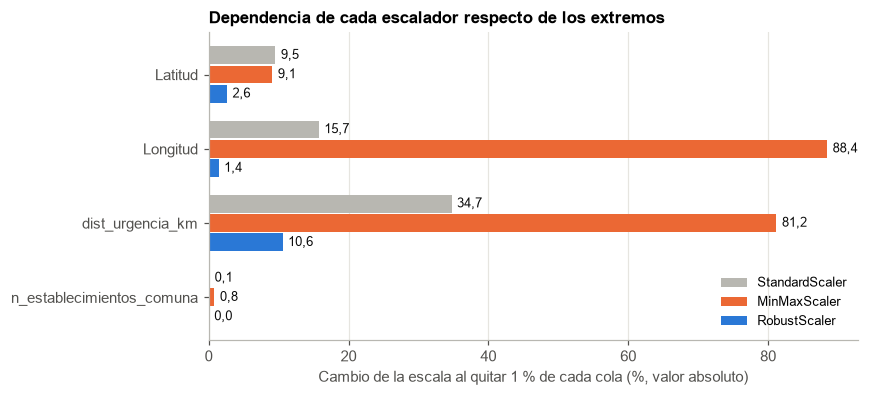

,mediana,rango_intercuartilico
Latitud,-33.8977,4.5978
Longitud,-71.2836,1.7189
dist_urgencia_km,0.6754,2.1283
n_establecimientos_comuna,28.0000,69.0000


[OK] Todas las columnas escaladas cumplen mediana 0 y rango intercuartílico 1.

In [22]:
A_ESCALAR = ["Latitud", "Longitud", "dist_urgencia_km", "n_establecimientos_comuna"]
tabla_escaladores = transformacion.comparar_escaladores(base, A_ESCALAR)
display(tabla_escaladores.round(3))
tabla_estabilidad = transformacion.estabilidad_escaladores(base, A_ESCALAR)
display(tabla_estabilidad.round(3))

asimetria = pd.DataFrame({"sin_transformar": base[A_ESCALAR].skew(),
                          "log1p": np.log1p(base[["dist_urgencia_km", "n_establecimientos_comuna"]]).skew()}).round(2)
display(asimetria)

figura = graficos.estabilidad_escaladores(tabla_estabilidad)
graficos.guardar(figura, RUTAS["figuras"] / "fig3_escaladores.png")
plt.show()

escaladas, parametros_escala = transformacion.escalar_robusto(base, A_ESCALAR)
display(pd.DataFrame(parametros_escala).T.round(4))
for columna in escaladas.columns:
    assert transformacion.verificar_propiedad_escalador(escaladas[columna], "robusto")
print("[OK] Todas las columnas escaladas cumplen mediana 0 y rango intercuartílico 1.")

def fila_estab(variable, escalador):
    """Devuelve la fila de estabilidad de una variable y un escalador."""
    return tabla_estabilidad[tabla_estabilidad["variable"].eq(variable) & tabla_estabilidad["escalador"].eq(escalador)].iloc[0]

resultados["escalamiento"] = {"tabla": tabla_escaladores.to_dict("records"), "estabilidad": tabla_estabilidad.to_dict("records"),
                              "parametros": parametros_escala, "asimetria": asimetria.to_dict()}
bitacora.registrar("transformación", "Escalar con RobustScaler Latitud, Longitud, dist_urgencia_km y n_establecimientos_comuna",
                   "Los extremos son reales y no se eliminan, como Isla de Pascua y las postas remotas; es coherente con imputar por mediana",
                   f"Al quitar 1 % de cada cola, la escala de longitud cambia {fmt(abs(fila_estab('Longitud','minmax')['cambio_escala_pct']))} % con MinMax, {fmt(abs(fila_estab('Longitud','estandar')['cambio_escala_pct']))} % con StandardScaler y {fmt(abs(fila_estab('Longitud','robusto')['cambio_escala_pct']))} % con RobustScaler; en distancia, {fmt(abs(fila_estab('dist_urgencia_km','minmax')['cambio_escala_pct']))} %, {fmt(abs(fila_estab('dist_urgencia_km','estandar')['cambio_escala_pct']))} % y {fmt(abs(fila_estab('dist_urgencia_km','robusto')['cambio_escala_pct']))} %",
                   f"StandardScaler y MinMax dependen más de los extremos; log1p reduce la asimetría de la distancia de {fmt(asimetria.loc['dist_urgencia_km','sin_transformar'],2)} a {fmt(asimetria.loc['dist_urgencia_km','log1p'],2)}, pero dificulta leer los kilómetros y se deja como opción para F3")

### 4.5 Ensamble de los conjuntos finales y justificación por transformación

El conjunto limpio conserva las categorías legibles; la matriz analítica contiene solo vigentes y solo números. La tabla justifica cada transformación en los tres planos que se exigen: pertinencia, impacto medido y coherencia con los objetivos.

In [23]:
COLUMNAS_LIMPIO = ["EstablecimientoCodigo", "EstablecimientoGlosa", "RegionCodigo", "RegionGlosa", "macrozona", "ComunaCodigo", "ComunaGlosa",
                   "SeremiSaludGlosa_ServicioDeSaludGlosa", "TipoPertenenciaEstabGlosa", "TipoEstablecimientoGlosa", "AmbitoFuncionamiento", "Certificacion",
                   "DependenciaAdministrativa", "TipoSistemaSaludGlosa", "NivelAtencionEstabglosa", "NivelComplejidadEstabGlosa", "TipoAtencionEstabGlosa",
                   "TieneServicioUrgencia", "TipoUrgencia", "ClasificacionTipoSapu", "EstadoFuncionamiento", "vigente", "es_referencia_urgencia",
                   "ref_sin_sur", "ref_ueh", "ref_ueh_pub_am", "ref_ueh_pub_a", "ref_sin_sapu_corto", "Latitud", "Longitud", "Latitud_imputada", "dist_urgencia_km", "dist_sin_sur_km",
                   "dist_ueh_km", "dist_ueh_pub_am_km", "dist_ueh_pub_a_km", "n_establecimientos_comuna", "FechaInicioFuncionamientoEstab", "FechaCierre",
                   "fecha_inicio_registrada", "fecha_inicio_2009", "antiguedad_anios", "antiguedad_con_2009", "tiene_madre", "posible_duplicado"]
limpio = trabajo[COLUMNAS_LIMPIO].copy()

modelo = pd.concat([base[["EstablecimientoCodigo"]], escaladas, matriz_binaria, *partes_ordinales, matriz_one_hot], axis=1)
print("Conjunto limpio:", limpio.shape, "| matriz analítica:", modelo.shape)

ce = resultados["coordenadas"]
JUSTIFICACION = [
    ("Unificación de categorías", "Una categoría no debe contarse dos veces", f"{filas_mapeadas} valores; 0 variantes restantes", "OE1 a OE4: cada categoría se cuenta una sola vez"),
    ("Casting de fechas y coordenadas", "Permite calcular antigüedad y distancia", "0 fallas de conversión", "OE1 y OE4"),
    ("Anulación de coordenadas erróneas", "Un punto falso ubica mal al establecimiento y altera la distancia", f"{resultados['anomalias']['coordenadas_anuladas']} coordenadas anuladas", "OE1 y OE4: ubicación y distancia confiables"),
    ("Imputación de coordenadas por comuna", "La comuna predice la ubicación de un vigente", f"{ce['faltan_vigentes']} puntos; desviación {fmt(cl.loc['mediana por grupo','cambio_desv_pct'],2)} % en latitud; error mediano {fmt(ek.loc['mediana por comuna','error_mediano_km'],1)} km", "OE1 y OE4: incluir todos los vigentes"),
    ("Imputación categórica con pureza", "Solo se completa lo casi determinado por el tipo", f"Acierto {fmt(comp.loc[n_pureza,'acierto_sobre_cubiertos_pct'])} % en complejidad", "OE3: niveles de complejidad completos"),
    ("Distancia a urgencia por niveles", "Describe el reparto territorial de la urgencia y depende de qué cuenta como urgencia", f"Nivel 1: mediana {fmt(dist_t['mediana'],2)} km; máximo {fmt(dist_t['max'],1)} km", "OE4"),
    ("Conteo por comuna", "Resume alta cardinalidad; no reemplaza el requisito de una discreta real", f"Evita {trabajo.loc[es_vigente, 'ComunaCodigo'].nunique()} columnas", "OE1: concentración comunal"),
    ("Antigüedad sin imputar", "Imputar podría crear diferencias entre sectores", f"Reduciría la desviación en {fmt(abs(ca.loc['mediana por grupo','cambio_desv_pct']))} %", "Ningún objetivo la requiere; evita crear diferencias entre sectores"),
    ("Codificación ordinal declarada", "El orden pertenece al dominio", "Alta=3, Mediana=2, Baja=1; 0 fuera de escala", "OE3"),
    ("One-hot con agrupación", "Las nominales no tienen orden", f"{resultados['codificacion']['one_hot_total']} columnas; cada grupo suma 1", "OE2 y OE3: entrada de F3"),
    ("Escalamiento robusto", "Hay extremos reales que no se eliminan", f"Mediana 0 y RIC 1 verificados; al recortar, la escala de longitud cambia {fmt(abs(fila_estab('Longitud','robusto')['cambio_escala_pct']))} % frente a {fmt(abs(fila_estab('Longitud','minmax')['cambio_escala_pct']))} % con MinMax", "OE5: variables comparables en F3"),
]
tabla_justificacion = pd.DataFrame(JUSTIFICACION, columns=["transformacion", "pertinencia", "impacto_medido", "coherencia_objetivos"])
tabla_justificacion.to_csv(RUTAS["docs"] / "justificacion_transformaciones.csv", index=False, encoding="utf-8")
resultados["justificacion"] = tabla_justificacion.to_dict("records")
display(tabla_justificacion)

Conjunto limpio:

(5837, 45)

| matriz analítica:

(5406, 71)

,transformacion,pertinencia,impacto_medido,coherencia_objetivos
0,Unificación de categorías,Una categoría no debe contarse dos veces,380 valores; 0 variantes restantes,OE1 a OE4: cada categoría se cuenta una sola vez
1,Casting de fechas y coordenadas,Permite calcular antigüedad y distancia,0 fallas de conversión,OE1 y OE4
2,Anulación de coordenadas erróneas,Un punto falso ubica mal al establecimiento y altera la distancia,4 coordenadas anuladas,OE1 y OE4: ubicación y distancia confiables
3,Imputación de coordenadas por comuna,La comuna predice la ubicación de un vigente,"82 puntos; desviación -0,22 % en latitud; error mediano 2,1 km",OE1 y OE4: incluir todos los vigentes
4,Imputación categórica con pureza,Solo se completa lo casi determinado por el tipo,"Acierto 99,4 % en complejidad",OE3: niveles de complejidad completos
5,Distancia a urgencia por niveles,Describe el reparto territorial de la urgencia y depende de qué cuenta como ...,"Nivel 1: mediana 0,68 km; máximo 248,7 km",OE4
6,Conteo por comuna,Resume alta cardinalidad; no reemplaza el requisito de una discreta real,Evita 344 columnas,OE1: concentración comunal
7,Antigüedad sin imputar,Imputar podría crear diferencias entre sectores,"Reduciría la desviación en 32,8 %",Ningún objetivo la requiere; evita crear diferencias entre sectores
8,Codificación ordinal declarada,El orden pertenece al dominio,"Alta=3, Mediana=2, Baja=1; 0 fuera de escala",OE3
9,One-hot con agrupación,Las nominales no tienen orden,56 columnas; cada grupo suma 1,OE2 y OE3: entrada de F3


## 5. Validación

**Lógica del bloque.** Validar es demostrar. Las comprobaciones usan `assert` y detienen el cuaderno donde se origina el problema: si una falla, hay que volver a la limpieza, como prevé el mapa. Se validan los conjuntos, se prueban las funciones en casos normales, límite y de excepción, y se ejecuta la batería automatizada.

### 5.1 Integridad del conjunto limpio y de la matriz analítica

In [24]:
NULOS_ADMITIDOS = {"Latitud": "solo en cerrados", "Longitud": "solo en cerrados", "dist_urgencia_km": "solo en cerrados",
                   "dist_sin_sur_km": "solo en cerrados", "dist_ueh_km": "solo en cerrados", "dist_ueh_pub_am_km": "solo en cerrados",
                   "dist_ueh_pub_a_km": "solo en cerrados",
                   "FechaInicioFuncionamientoEstab": "faltante real, sin imputar", "FechaCierre": "estructural en vigentes; 77 cerrados sin fecha",
                   "antiguedad_anios": "derivada de la fecha, sin imputar", "antiguedad_con_2009": "derivada de la fecha, sin imputar"}
control_limpio = validacion.validar_limpio(limpio, crudo, NULOS_ADMITIDOS)
display(control_limpio)

ESCALADAS = list(escaladas.columns)
control_modelo = validacion.validar_modelo(modelo, n_esperado=int(trabajo["vigente"].sum()), grupos_one_hot=grupos_one_hot,
                                           ordinales={"nivel_atencion_ord": 3, "complejidad_ord": 3}, columnas_escaladas=ESCALADAS)
display(control_modelo)
assert pd.util.hash_pandas_object(crudo, index=True).sum() == firma_crudo, "El DataFrame crudo fue alterado."
print("[OK] El DataFrame crudo no fue alterado por el flujo.")
aprobadas_modelo = int(control_modelo["resultado"].eq("OK").sum())
print(f"Comprobaciones aprobadas: {len(control_limpio)} del conjunto limpio y {aprobadas_modelo} de la matriz analítica.")
duplicados_modelo = validacion.describir_duplicados(modelo)
print("Filas iguales al excluir la llave:", duplicados_modelo)
resultados["validacion"] = {"limpio": len(control_limpio), "modelo": aprobadas_modelo, "duplicados_sin_llave": duplicados_modelo}

,comprobacion,resultado,detalle
0,Se conserva el número de filas del crudo,OK,5837 de 5837
1,La llave EstablecimientoCodigo es única,OK,
2,Las llaves coinciden con las del crudo,OK,
3,Solo hay nulos en columnas declaradas,OK,fuera de lo declarado: []
4,Ningún vigente tiene fecha de cierre,OK,
5,Todo vigente tiene coordenadas,OK,
6,Latitud dentro de Chile continental e insular,OK,[-56; -17]
7,Longitud dentro de Chile continental e insular,OK,[-110; -66]
8,El código de comuna empieza con el código de región,OK,
9,La antigüedad observada no es negativa,OK,


,comprobacion,resultado,detalle
0,Se conservan las filas vigentes esperadas,OK,5406 de 5406
1,No quedan valores nulos,OK,
2,Todos los atributos son numéricos,OK,[]
3,No hay valores infinitos,OK,
4,La llave es única,OK,
5,Filas repetidas sin considerar la llave,INFORMA,88 repetidas en 143 filas
6,El grupo one-hot RegionGlosa suma 1 por fila,OK,16 columnas
7,El grupo one-hot tipo_grupo suma 1 por fila,OK,17 columnas
8,El grupo one-hot dependencia_grupo suma 1 por fila,OK,5 columnas
9,El grupo one-hot TipoSistemaSaludGlosa suma 1 por fila,OK,6 columnas


[OK] El DataFrame crudo no fue alterado por el flujo.

Comprobaciones aprobadas: 11 del conjunto limpio y 20 de la matriz analítica.

Filas iguales al excluir la llave:

{'repetidas': 88, 'filas_involucradas': 143, 'con_coordenada_imputada': 28, 'con_posible_duplicado': 2}

### 5.2 Casos normales, límite y de excepción

La tabla conserva qué se probó y qué resultó. Incluye columna sin nulos, una sola categoría, tipos inesperados, categorías no declaradas, referencias vacías y archivo incorrecto.

In [25]:
casos = validacion.casos_verificacion()
display(casos)
print(casos.groupby(["caso", "resultado"]).size().to_string())
assert casos["resultado"].eq("OK").all(), "Hay casos de verificación que fallan."
resultados["casos"] = {"total": len(casos), **casos["caso"].value_counts().to_dict(), "tabla": casos.to_dict("records")}

,funcion,caso,que_verifica,resultado
0,normalizar_texto,normal,colapsa espacios internos y extremos,OK
1,normalizar_texto,límite,conserva el nulo,OK
2,normalizar_texto,excepción,rechaza una columna numérica,OK
3,aplicar_mapeos,normal,unifica la variante,OK
4,aplicar_mapeos,límite,sin coincidencias informa 0 filas,OK
5,aplicar_mapeos,excepción,rechaza una columna inexistente,OK
6,convertir_fechas,normal,interpreta día antes que mes,OK
7,convertir_fechas,excepción,una fecha imposible queda como faltante y se informa,OK
8,imputar_categorica_por_grupo,normal,imputa la moda de un grupo homogéneo,OK
9,imputar_categorica_por_grupo,límite,un grupo heterogéneo queda como Sin dato,OK


caso       resultado
excepción  OK           12
límite     OK            8
normal     OK            8

### 5.3 Pruebas automatizadas

Se ejecutan como un proceso aparte, igual que lo haría cualquier integrante desde la terminal, y su salida queda conservada.

In [26]:
salida_tests = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", ".", "-v"], cwd=RAIZ,
                              capture_output=True, text=True, encoding="utf-8", env={**os.environ, "PYTHONIOENCODING": "utf-8"})
print(salida_tests.stderr)
assert salida_tests.returncode == 0, "Las pruebas automatizadas fallaron."
total_pruebas = int(salida_tests.stderr.split("Ran ")[1].split(" test")[0])
resultados["pruebas"] = {"total": total_pruebas, "resultado": "OK"}

test_forma_y_ceros_iniciales (tests.test_datos.TestDatos.test_forma_y_ceros_iniciales) ... ok
test_crudo_conserva_su_huella (tests.test_datos.TestEntorno.test_crudo_conserva_su_huella) ... ok
test_localiza_raiz_desde_subcarpeta (tests.test_datos.TestEntorno.test_localiza_raiz_desde_subcarpeta) ... ok
test_raiz_inexistente (tests.test_datos.TestEntorno.test_raiz_inexistente) ... ok
test_requirements_exige_version (tests.test_datos.TestEntorno.test_requirements_exige_version) ... ok
test_ambiente_no_depende_de_la_ruta (tests.test_datos.TestEntornoFlexible.test_ambiente_no_depende_de_la_ruta) ... ok
test_composicion (tests.test_definicion.TestAuditoria.test_composicion) ... ok
test_discrepancias (tests.test_definicion.TestAuditoria.test_discrepancias) ... ok
test_variante_e_incorporacion (tests.test_definicion.TestAuditoria.test_variante_e_incorporacion) ... ok
test_bitacora_exige_motivo (tests.test_definicion.TestBitacora.test_bitacora_exige_motivo) ... ok
test_diccionario_cubre_todas_la

### 5.4 Resultados intermedios y visualización de control

Se comparan indicadores antes y después, y se revisa el perfil de la matriz final. Las cajas de las variables escaladas deben quedar centradas en 0, con los extremos reales visibles a un lado: esa es la evidencia de que el escalamiento no los eliminó. Las filas iguales al excluir la llave se informan arriba: tienen el mismo perfil y la misma ubicación, por lo que no se eliminan.

,indicador,crudo,limpio,modelo
0,Filas,5837,5837,5406
1,Columnas,33,45,71
2,Nulos totales,29326,17280,0
3,Filas duplicadas exactas,0,0,0
4,Coordenadas faltantes en vigentes,79,0,0


,nulos_declarados,condicion
Latitud,348,solo en cerrados
Longitud,348,solo en cerrados
dist_urgencia_km,431,solo en cerrados
dist_sin_sur_km,431,solo en cerrados
dist_ueh_km,431,solo en cerrados
dist_ueh_pub_am_km,431,solo en cerrados
dist_ueh_pub_a_km,431,solo en cerrados
FechaInicioFuncionamientoEstab,2729,"faltante real, sin imputar"
FechaCierre,5483,estructural en vigentes; 77 cerrados sin fecha
antiguedad_anios,3488,"derivada de la fecha, sin imputar"


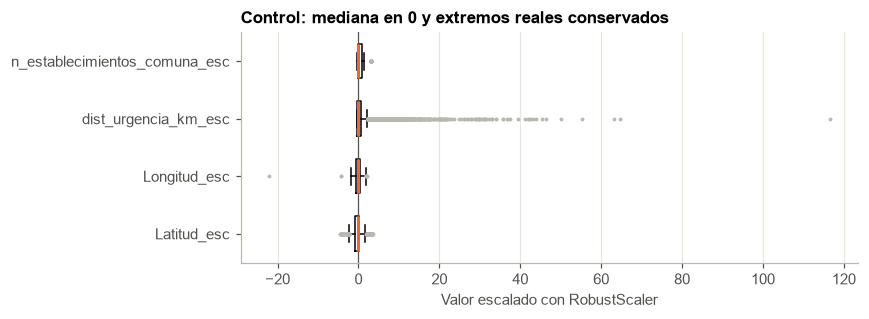

In [27]:
resumen = pd.DataFrame([
    {"indicador": "Filas", "crudo": crudo.shape[0], "limpio": limpio.shape[0], "modelo": modelo.shape[0]},
    {"indicador": "Columnas", "crudo": crudo.shape[1], "limpio": limpio.shape[1], "modelo": modelo.shape[1]},
    {"indicador": "Nulos totales", "crudo": int(crudo.isna().sum().sum()), "limpio": int(limpio.isna().sum().sum()), "modelo": int(modelo.isna().sum().sum())},
    {"indicador": "Filas duplicadas exactas", "crudo": int(crudo.duplicated().sum()), "limpio": int(limpio.duplicated().sum()), "modelo": int(modelo.duplicated().sum())},
    {"indicador": "Coordenadas faltantes en vigentes", "crudo": int(crudo.loc[vista["estado"].eq("vigente"), "Latitud"].isna().sum()), "limpio": int(limpio.loc[limpio["vigente"].eq(1), "Latitud"].isna().sum()), "modelo": 0},
])
display(resumen)
display(limpio[list(NULOS_ADMITIDOS)].isna().sum().rename("nulos_declarados").to_frame().assign(condicion=pd.Series(NULOS_ADMITIDOS)))
resultados["resumen"] = resumen.to_dict("records")
resultados["nulos_limpio"] = limpio[list(NULOS_ADMITIDOS)].isna().sum().to_dict()
resultados["cerrados_sin_fecha"] = int((limpio["vigente"].eq(0) & limpio["FechaCierre"].isna()).sum())

figura, eje = plt.subplots(figsize=(8, 3))
eje.boxplot([modelo[c] for c in ESCALADAS], orientation="horizontal", tick_labels=ESCALADAS, widths=0.6,
            flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": graficos.COLOR_NEUTRO, "markeredgecolor": "none"},
            medianprops={"color": graficos.COLOR_ACENTO, "linewidth": 2})
eje.axvline(0, color=graficos.COLOR_TEXTO_2, linewidth=0.8)
eje.set_xlabel("Valor escalado con RobustScaler")
eje.grid(axis="y", visible=False)
eje.set_title("Control: mediana en 0 y extremos reales conservados")
figura.tight_layout()
graficos.guardar(figura, RUTAS["figuras"] / "fig4_control_escala.png")
plt.show()

## 6. Resultados preliminares por objetivo específico

**Lógica del bloque.** Responde con estadística descriptiva los cinco objetivos específicos de la Fase 1: uno por cada dimensión de análisis del informe (geográfica, administrativa, asistencial y de servicios) y un quinto que las cruza. Se calcula sobre los establecimientos **vigentes** del conjunto limpio, que conserva las categorías legibles. Las funciones están en `src/descriptivo.py`.

**Qué no se afirma.** Son descripciones del registro. No miden el acceso efectivo de la población, la calidad de las prestaciones ni la suficiencia de la infraestructura, porque el conjunto no trae población, demanda ni capacidad. `No Aplica` y `Sin dato` se muestran en las frecuencias, pero se excluyen al medir asociaciones, porque no son categorías del fenómeno.

### 6.1 OE1 · Distribución geográfica

,objetivo,dimension,pregunta,conceptos,objetivo_f1
0,OE1,Geográfica,¿Dónde están?,"Región, Comuna, Latitud, Longitud","Describir la distribución por región, comuna y coordenadas disponibles."
1,OE2,Administrativa,¿Cómo se organizan?,"Dependencia administrativa, Pertenencia al SNSS, Tipo de prestador","Caracterizar dependencia administrativa, pertenencia al SNSS y tipo de prestador."
2,OE3,Asistencial,¿Qué características tienen?,"Tipo de establecimiento, Nivel de atención, Nivel de complejidad, Modalidad de atención","Analizar tipo de establecimiento, nivel de atención, complejidad y modalidad."
3,OE4,Servicios,¿Qué servicios registran?,"Disponibilidad de urgencia, Tipo de urgencia",Examinar la disponibilidad y distribución territorial de los servicios de urgencia.
4,OE5,Integrada,¿Qué patrones aparecen al cruzarlas?,Pares de variables de dimensiones distintas,Identificar patrones y diferencias mediante el análisis integrado de las dimensiones.


Vigentes: 5406 en 16 regiones y 344 comunas

,establecimientos,comunas,pct,por_comuna
RegionGlosa,,,,
Metropolitana de Santiago,1090,52,20.2,21.0
Coquimbo,638,15,11.8,42.5
Maule,539,30,10.0,18.0
La Araucanía,457,32,8.5,14.3
Los Lagos,450,30,8.3,15.0
Biobío,442,33,8.2,13.4
Valparaíso,431,38,8.0,11.3
Libertador Gral. B. O'Higgins,295,33,5.5,8.9
Los Ríos,207,12,3.8,17.2


,n,pct
macrozona,,
Norte,1194,22.1
Centro,2523,46.7
Sur,1556,28.8
Austral,133,2.5


,ComunaCodigo,ComunaGlosa,establecimientos
0,04101,La Serena,248
1,07101,Talca,127
2,15101,Arica,117
3,04301,Ovalle,113
4,13123,Providencia,109
5,09101,Temuco,104
6,02101,Antofagasta,100
7,10101,Puerto Montt,99
8,13101,Santiago,99
9,04102,Coquimbo,89


Por comuna: mediana 8, máximo 248 (La Serena); Gini comunal 0,56; las 10 comunas con más establecimientos reúnen el 22,3 %

Vigentes con coordenada imputada: 82 | sin coordenada: 0

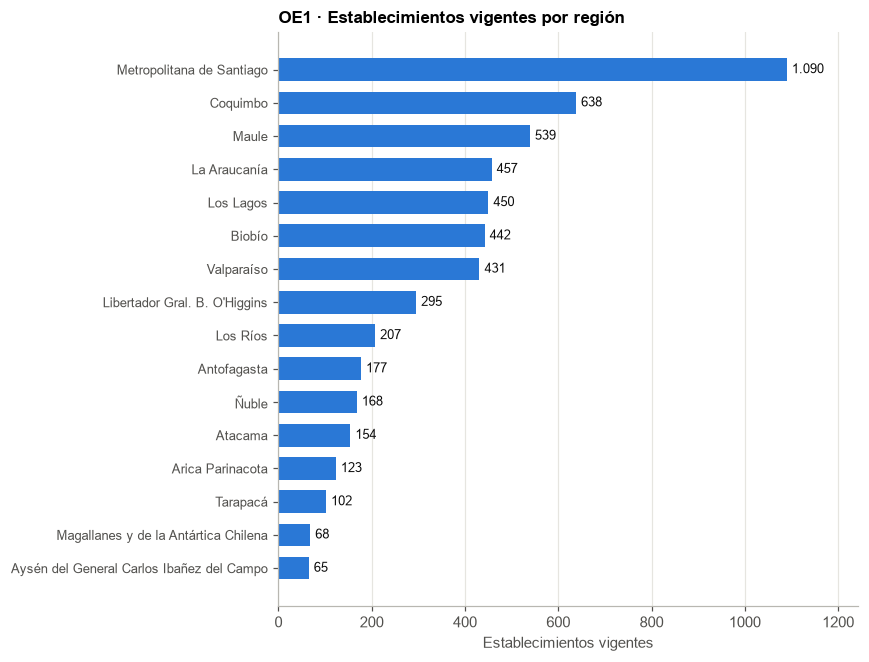

In [28]:
vigentes_limpio = limpio[limpio["vigente"].eq(1)].copy()

# Cada objetivo de la Fase 1 debe tener una dimensión que lo responda.
objetivos_f1 = json.loads((RUTAS["docs"] / "metadatos_fase1.json").read_text(encoding="utf-8"))["objetivos_especificos"]
filas_dim = [{"objetivo": d["objetivo"], "dimension": n, "pregunta": d["pregunta"],
              "conceptos": ", ".join(descriptivo.CONCEPTOS[v] for v in d["variables"])} for n, d in descriptivo.DIMENSIONES.items()]
filas_dim.append({"objetivo": "OE5", "dimension": "Integrada", "pregunta": "¿Qué patrones aparecen al cruzarlas?",
                  "conceptos": "Pares de variables de dimensiones distintas"})
tabla_dimensiones = pd.DataFrame(filas_dim)
assert len(objetivos_f1) == len(tabla_dimensiones) == 5, "La Fase 1 debe declarar cinco objetivos específicos."
tabla_dimensiones["objetivo_f1"] = objetivos_f1
pd.set_option("display.max_colwidth", None)
display(tabla_dimensiones)
pd.set_option("display.max_colwidth", 80)

oe1 = descriptivo.distribucion_territorial(vigentes_limpio)
r1 = oe1["resumen"]
print(f"Vigentes: {r1['establecimientos']} en {r1['regiones']} regiones y {r1['comunas']} comunas")
display(oe1["por_region"].round(1))
display(oe1["por_macrozona"].round(1))
display(oe1["comunas_mayores"])
print(f"Por comuna: mediana {fmt(r1['mediana_por_comuna'], 0)}, máximo {r1['maximo_por_comuna']} ({r1['comuna_maxima']}); "
      f"Gini comunal {fmt(r1['gini_comunal'], 2)}; las 10 comunas con más establecimientos reúnen el {fmt(r1['pct_en_10_comunas'])} %")
print(f"Vigentes con coordenada imputada: {r1['coordenada_imputada']} | sin coordenada: {r1['sin_coordenada']}")

figura = graficos.barras_horizontales(oe1["por_region"]["establecimientos"], "OE1 · Establecimientos vigentes por región",
                                      "Establecimientos vigentes")
graficos.guardar(figura, RUTAS["figuras"] / "fig5_establecimientos_region.png")
plt.show()

**Lectura OE1.** La Región Metropolitana reúne el 20,2 % de los vigentes. Coquimbo es segunda, con 11,8 %, por delante de Maule, La Araucanía y Valparaíso, y La Serena es la comuna con más establecimientos (248). La mitad de las comunas registra 8 establecimientos o menos, y el Gini comunal de 0,56 indica que la oferta registrada se concentra en pocas comunas. La posición de Coquimbo se explica en OE2.

### 6.2 OE2 · Composición administrativa e institucional

In [29]:
oe2 = descriptivo.composicion_administrativa(vigentes_limpio)
for tabla in oe2["tablas"].values():
    display(tabla.round(1))
display(oe2["cruce_prestador_snss"])
r2 = oe2["resumen"]
print(f"Públicos {fmt(r2['pct_publico'])} % | privados {fmt(r2['pct_privado'])} % | en el SNSS {fmt(r2['pct_snss'])} % | "
      f"dependencia principal: {r2['dependencia_principal']} ({fmt(r2['pct_dependencia_principal'])} %) | públicos fuera del SNSS: {r2['publicos_fuera_snss']}")

privados_region = (100 * pd.crosstab(vigentes_limpio["RegionGlosa"], vigentes_limpio["TipoSistemaSaludGlosa"],
                                     normalize="index")["Privado"]).sort_values(ascending=False)
print("Regiones con mayor proporción de privados (%):", privados_region.head(3).round(1).to_dict())
tipos_coquimbo = vigentes_limpio[vigentes_limpio["RegionGlosa"].eq("Coquimbo") & vigentes_limpio["TipoSistemaSaludGlosa"].eq("Privado")]
print("Tipos privados más frecuentes en Coquimbo:", tipos_coquimbo["TipoEstablecimientoGlosa"].value_counts().head(4).to_dict())

,n,pct
DependenciaAdministrativa,,
Municipal,2562,47.4
Privado,2157,39.9
Servicio de Salud,517,9.6
Otra Institución,47,0.9
Carabineros,34,0.6
Gendarmería,33,0.6
Ejército de Chile,15,0.3
Armada de Chile,15,0.3
Delegado,10,0.2


,n,pct
TipoPertenenciaEstabGlosa,,
Perteneciente al Sistema Nacional de Servicios de Salud,3096,57.3
No Perteneciente al Sistema Nacional de Servicios de Salud,2269,42.0
No Aplica,41,0.8


,n,pct
TipoSistemaSaludGlosa,,
Público,3090,57.2
Privado,2164,40.0
Fuerzas Armadas y de Orden (FFAA),73,1.4
No Aplica,40,0.7
Gendarmería,33,0.6
Sin dato,6,0.1


TipoPertenenciaEstabGlosa,No Aplica,No Perteneciente al Sistema Nacional de Servicios de Salud,Perteneciente al Sistema Nacional de Servicios de Salud,Total
TipoSistemaSaludGlosa,,,,
Fuerzas Armadas y de Orden (FFAA),0,73,0,73
Gendarmería,0,33,0,33
No Aplica,40,0,0,40
Privado,0,2163,1,2164
Público,1,0,3089,3090
Sin dato,0,0,6,6
Total,41,2269,3096,5406


Públicos 57,2 % | privados 40,0 % | en el SNSS 57,3 % | dependencia principal: Municipal (47,4 %) | públicos fuera del SNSS: 1

Regiones con mayor proporción de privados (%):

{'Coquimbo': 69.4, 'Arica Parinacota': 66.7, 'Antofagasta': 60.5}

Tipos privados más frecuentes en Coquimbo:

{'Centro de Salud Privado': 141, 'Clínica Dental': 123, 'Centro de Especialidades': 65, 'Sala Externa de Toma de Muestras (SETM)': 47}

**Lectura OE2.** El 57,2 % de los vigentes es público y el 40,0 %, privado. La pertenencia al SNSS coincide casi uno a uno con el tipo de prestador, y la dependencia municipal es la más frecuente, con 47,4 %. En Coquimbo el 69 % de los vigentes es privado, la proporción más alta del país, sobre todo centros de salud privados, clínicas dentales y centros de especialidades. El registro no permite saber si eso refleja más oferta privada o un registro más completo de los privados en esa región: es un punto que conviene verificar antes de comparar regiones.

### 6.3 OE3 · Características asistenciales

In [30]:
oe3 = descriptivo.caracteristicas_asistenciales(vigentes_limpio)
display(oe3["tipos"].round(1))
display(oe3["nivel"].round(1))
display(oe3["complejidad"].round(1))
display(oe3["modalidad"].round(1))
display(oe3["cruce_nivel_complejidad"])
r3 = oe3["resumen"]
print(f"{r3['tipos']} tipos; el más frecuente es {r3['tipo_principal']} ({fmt(r3['pct_tipo_principal'])} %); los 10 primeros suman {fmt(r3['pct_10_tipos'])} %")
print(f"Primer nivel {fmt(r3['pct_primer_nivel'])} % | nivel No Aplica {fmt(r3['pct_nivel_no_aplica'])} % | "
      f"baja complejidad {fmt(r3['pct_baja'])} % | alta {fmt(r3['pct_alta'])} % | ambulatoria {fmt(r3['pct_ambulatoria'])} %")

,n,pct
TipoEstablecimientoGlosa,,
Posta de Salud Rural (PSR),1116,20.6
Centro de Salud Privado,874,16.2
Centro de Salud Familiar (CESFAM),607,11.2
Laboratorio Clínico,368,6.8
Clínica Dental,366,6.8
Centro Comunitario de Salud Familiar (CECOSF),302,5.6
Servicio de Atención Primaria de Urgencia (SAPU),240,4.4
Hospital,228,4.2
Servicio de Urgencia Rural (SUR),181,3.3


,n,pct
NivelAtencionEstabglosa,,
Primer Nivel,2809,52.0
Segundo Nivel,1253,23.2
Tercer Nivel,145,2.7
No Aplica,1199,22.2


,n,pct
NivelComplejidadEstabGlosa,,
Baja Complejidad,3276,60.6
Mediana Complejidad,1208,22.3
Alta Complejidad,127,2.3
No Aplica,748,13.8
Sin dato,47,0.9


,n,pct
TipoAtencionEstabGlosa,,
Atención Abierta-Ambulatoria,5016,92.8
Atención Cerrada-Hospitalaria,343,6.3
No Aplica,47,0.9


NivelComplejidadEstabGlosa,Baja Complejidad,Mediana Complejidad,Alta Complejidad,No Aplica,Sin dato
NivelAtencionEstabglosa,,,,,
Primer Nivel,2798,7,1,2,1
Segundo Nivel,306,916,8,3,20
Tercer Nivel,10,16,113,1,5
No Aplica,162,269,5,742,21


29 tipos; el más frecuente es Posta de Salud Rural (PSR) (20,6 %); los 10 primeros suman 82,0 %

Primer nivel 52,0 % | nivel No Aplica 22,2 % | baja complejidad 60,6 % | alta 2,3 % | ambulatoria 92,8 %

**Lectura OE3.** La red registrada es mayoritariamente de atención primaria y ambulatoria: 52,0 % de primer nivel, 60,6 % de baja complejidad y 92,8 % de atención abierta. La posta de salud rural es el tipo más frecuente, con 20,6 %. La alta complejidad es escasa (2,3 %) y casi toda corresponde al tercer nivel. El 22,2 % no tiene nivel de atención aplicable, sobre todo laboratorios, clínicas dentales, centros de diálisis y salas de toma de muestras, que no se clasifican en niveles: no es un faltante, sino una condición del registro.

### 6.4 OE4 · Servicios de urgencia

,n,pct
TieneServicioUrgencia,,
SI,783,14.5
NO,4439,82.1
No Aplica,183,3.4
Sin dato,1,0.0


,n,pct
TipoUrgencia,,
Urgencia Hospitalaria (UEH),247,31.5
Urgencia Ambulatoria (SAPU),236,30.1
Urgencia Ambulatoria (SUR),181,23.1
Urgencia Ambulatoria (SAR),104,13.3
Hospitalaria Especializada,7,0.9
SAPU Dental,4,0.5
Otro,2,0.3
Urgencia Ambulatoria Privada,2,0.3


,establecimientos,con_urgencia,pct_con_urgencia
RegionGlosa,,,
Tarapacá,102,22,21.6
Ñuble,168,36,21.4
Valparaíso,431,89,20.6
Biobío,442,83,18.8
Magallanes y de la Antártica Chilena,68,12,17.6
Metropolitana de Santiago,1090,187,17.2
Libertador Gral. B. O'Higgins,295,48,16.3
Los Ríos,207,32,15.5
Antofagasta,177,27,15.3


,establecimientos,con_urgencia,pct_con_urgencia
TipoSistemaSaludGlosa,,,
Público,3090,714,23.1
Fuerzas Armadas y de Orden (FFAA),73,9,12.3
Privado,2164,60,2.8
Gendarmería,33,0,0.0
No Aplica,40,0,0.0
Sin dato,6,0,0.0


,establecimientos,mediana_km,p75_km,maximo_km
macrozona,,,,
Norte,1081,0.6,1.3,138.1
Centro,2123,0.9,2.0,43.5
Sur,1331,1.4,11.7,66.3
Austral,115,1.4,35.1,248.7


Con urgencia declarada: 783 (14,5 %); tipo más frecuente: Urgencia Hospitalaria (UEH) (31,5 %)

Comunas sin ningún vigente con urgencia: 18 de 344

Mediana de la distancia al servicio de referencia más cercano, en vigentes que no lo son: 0,87 km

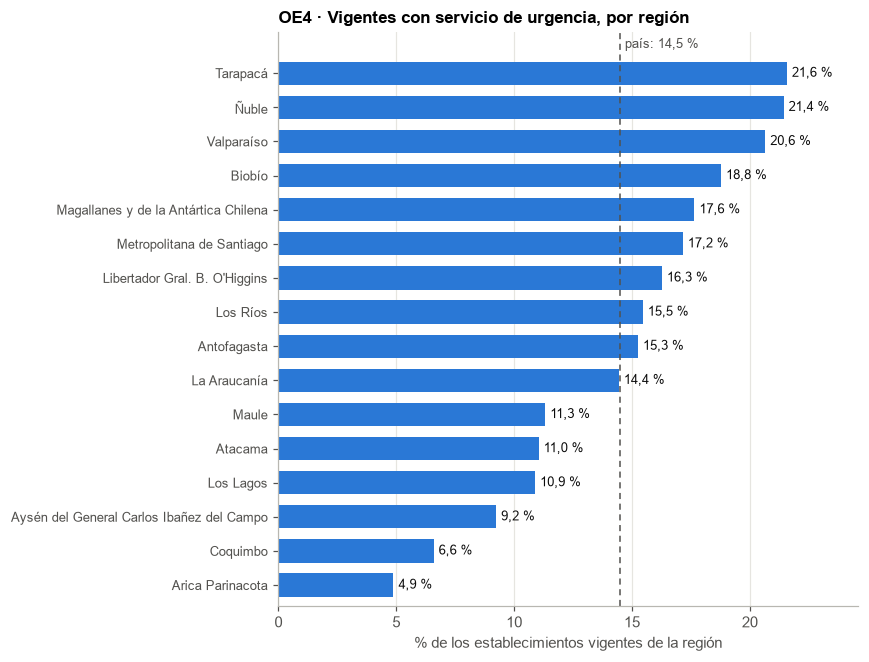

In [31]:
oe4 = descriptivo.servicios_urgencia(vigentes_limpio)
display(oe4["disponibilidad"].round(1))
display(oe4["tipos"].round(1))
display(oe4["por_region"].round(1))
display(oe4["por_prestador"].round(1))
display(oe4["distancia_macrozona"].round(1))
r4 = oe4["resumen"]
print(f"Con urgencia declarada: {r4['con_urgencia']} ({fmt(r4['pct_con_urgencia'])} %); tipo más frecuente: {r4['tipo_principal']} ({fmt(r4['pct_tipo_principal'])} %)")
print(f"Comunas sin ningún vigente con urgencia: {r4['comunas_sin_urgencia']} de {r4['comunas']}")
print(f"Mediana de la distancia al servicio de referencia más cercano, en vigentes que no lo son: {fmt(r4['mediana_km_sin_servicio'], 2)} km")

figura = graficos.barras_horizontales(oe4["por_region"]["pct_con_urgencia"], "OE4 · Vigentes con servicio de urgencia, por región",
                                      "% de los establecimientos vigentes de la región", decimales=1, sufijo=" %",
                                      referencia=r4["pct_con_urgencia"], texto_referencia=f"país: {fmt(r4['pct_con_urgencia'])} %")
graficos.guardar(figura, RUTAS["figuras"] / "fig6_urgencia_region.png")
plt.show()

**Lectura OE4.** El 14,5 % de los vigentes declara servicio de urgencia: UEH hospitalaria (31,5 %), SAPU (30,1 %), SUR (23,1 %) y SAR (13,3 %). La proporción varía entre regiones de 4,9 % en Arica y Parinacota a 21,6 % en Tarapacá, y es mucho mayor entre los públicos (23,1 %) que entre los privados (2,8 %). Coquimbo queda entre las más bajas, con 6,6 %, coherente con su alta proporción de privados. 18 comunas no registran ningún vigente con urgencia. La distancia en línea recta a la referencia más cercana tiene medianas bajas en todas las macrozonas, pero su cuartil superior crece hacia el sur: 1,3 km en Norte, 11,7 km en Sur y 35,1 km en Austral. Describe dónde están los servicios, no el acceso de la población.

### 6.5 OE5 · Patrones al cruzar las dimensiones

,variable_a,variable_b,dimension_a,dimension_b,n,categorias,v_cramer
0,DependenciaAdministrativa,NivelAtencionEstabglosa,Administrativa,Asistencial,4207,12 x 3,0.611
1,TipoSistemaSaludGlosa,NivelComplejidadEstabGlosa,Administrativa,Asistencial,4605,4 x 3,0.475
2,NivelComplejidadEstabGlosa,TieneServicioUrgencia,Asistencial,Servicios,4534,3 x 2,0.365
3,TipoSistemaSaludGlosa,TieneServicioUrgencia,Administrativa,Servicios,5214,4 x 2,0.278
4,macrozona,TipoSistemaSaludGlosa,Geográfica,Administrativa,5360,4 x 4,0.176
5,macrozona,NivelAtencionEstabglosa,Geográfica,Asistencial,4207,4 x 3,0.173
6,macrozona,TieneServicioUrgencia,Geográfica,Servicios,5222,4 x 2,0.075


,establecimientos,por_comuna,pct_publico,pct_primer_nivel,pct_alta_complejidad,pct_con_urgencia,mediana_km_urgencia
macrozona,,,,,,,
Norte,1194,27.1,33.9,32.7,1.2,9.5,0.6
Centro,2523,14.5,57.8,51.7,3.3,16.7,0.9
Sur,1556,14.5,73.5,67.2,1.6,14.8,1.4
Austral,133,7.0,62.4,50.4,3.0,13.5,1.4


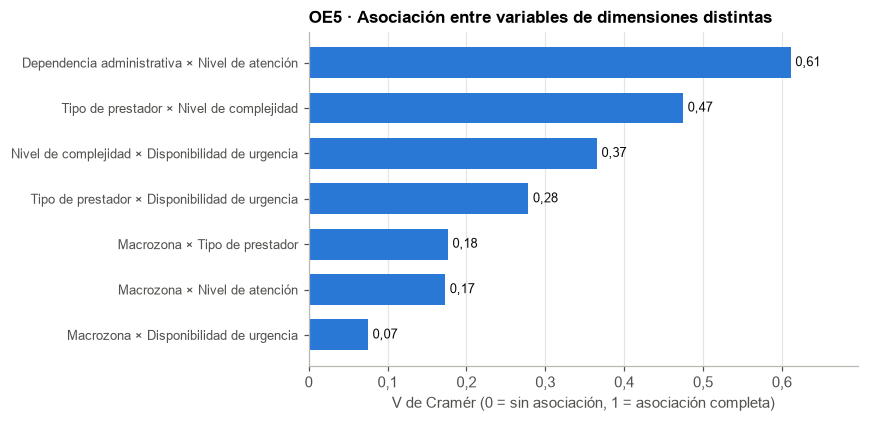

In [32]:
oe5 = descriptivo.asociaciones(vigentes_limpio)
display(oe5.round(3))
perfil = descriptivo.perfil_por_macrozona(vigentes_limpio)
display(perfil.round(1))

etiquetas = oe5.assign(par=[f"{descriptivo.CONCEPTOS.get(a, 'Macrozona')} × {descriptivo.CONCEPTOS.get(b, 'Macrozona')}"
                             for a, b in zip(oe5["variable_a"], oe5["variable_b"])]).set_index("par")["v_cramer"]
figura = graficos.barras_horizontales(etiquetas, "OE5 · Asociación entre variables de dimensiones distintas",
                                      "V de Cramér (0 = sin asociación, 1 = asociación completa)", decimales=2,
                                      alto_por_barra=0.42)
graficos.guardar(figura, RUTAS["figuras"] / "fig7_asociaciones.png")
plt.show()

**Lectura OE5.** Las asociaciones más fuertes unen la dimensión administrativa con la asistencial: la dependencia con el nivel de atención (V = 0,61) y el tipo de prestador con la complejidad (V = 0,47). Le siguen la complejidad con la urgencia (0,37) y el prestador con la urgencia (0,28). La macrozona se asocia poco con las demás variables (V ≤ 0,18): las diferencias territoriales existen, como muestra el perfil, pero pesan menos que quién administra el establecimiento. Norte tiene más establecimientos por comuna y menos públicos (33,9 %); Sur, la mayor proporción pública y de primer nivel. La V de Cramér mide el tamaño de la asociación en este registro y no es una prueba de hipótesis.

### 6.6 Síntesis por objetivo

| Objetivo | Hallazgo preliminar | Limitación |
| --- | --- | --- |
| OE1 | Región Metropolitana con 20,2 %, Coquimbo segunda; concentración comunal alta (Gini 0,56) | Sin población no se calculan tasas |
| OE2 | 57,2 % público; la pertenencia al SNSS coincide con el prestador; municipal es la dependencia principal | No se sabe si el registro de privados es igual de completo en todas las regiones |
| OE3 | Predominio de primer nivel, baja complejidad y atención ambulatoria; la posta rural es el tipo más frecuente | `No Aplica` es una condición, no un faltante |
| OE4 | 14,5 % con urgencia; mucho más en públicos; 18 comunas sin urgencia | La distancia es en línea recta y no mide acceso |
| OE5 | La administración se asocia con lo asistencial más que el territorio | Asociación descriptiva, sin contraste formal, que corresponde a la Fase 3 |

In [33]:
def tabla_json(tabla):
    """Convierte una tabla a registros, conservando el índice como columna."""
    return tabla.reset_index().to_dict("records")

resultados["descriptivo"] = {
    "dimensiones": tabla_dimensiones.to_dict("records"),
    "oe1": {"resumen": r1, "por_region": tabla_json(oe1["por_region"]), "por_macrozona": tabla_json(oe1["por_macrozona"]),
            "comunas_mayores": oe1["comunas_mayores"].to_dict("records")},
    "oe2": {"resumen": r2, "tablas": {k: tabla_json(v) for k, v in oe2["tablas"].items()},
            "privados_por_region": privados_region.round(2).to_dict()},
    "oe3": {"resumen": r3, **{k: tabla_json(oe3[k]) for k in ("tipos", "nivel", "complejidad", "modalidad")}},
    "oe4": {"resumen": r4, **{k: tabla_json(oe4[k]) for k in ("disponibilidad", "tipos", "por_region", "por_prestador", "distancia_macrozona")}},
    "oe5": {"asociaciones": oe5.to_dict("records"), "perfil_macrozona": tabla_json(perfil)},
}
dependencia_nivel = oe5[oe5["variable_a"].eq("DependenciaAdministrativa")].iloc[0]
bitacora.registrar("análisis", "Describir los cinco objetivos sobre los establecimientos vigentes del conjunto limpio",
                   "Los cerrados no forman parte de la red actual; mezclarlos alteraría la composición que se describe",
                   f"{len(vigentes_limpio)} vigentes de {len(limpio)} registros",
                   "Describir todo el registro, incluidos los cerrados")
bitacora.registrar("análisis", "Mostrar No Aplica y Sin dato en las frecuencias y excluirlos al medir asociaciones",
                   "Son condiciones del registro, no categorías del fenómeno; dentro de un cruce inflarían la asociación",
                   f"Dependencia × nivel de atención se mide con {dependencia_nivel['n']} de {len(vigentes_limpio)} vigentes",
                   "Eliminarlos de todas las tablas, lo que ocultaría cuántos son")
bitacora.registrar("análisis", "Medir la asociación entre dimensiones con la V de Cramér, sin valor p",
                   "El objetivo es descriptivo y el registro es casi censal: un valor p no mediría error de muestreo",
                   f"Mayor asociación: dependencia × nivel de atención, V = {fmt(dependencia_nivel['v_cramer'], 2)}; macrozona con otras dimensiones, V ≤ {fmt(oe5[oe5['variable_a'].eq('macrozona')]['v_cramer'].max(), 2)}",
                   "Prueba chi cuadrado, que la Fase 3 puede plantear con una regla fijada de antemano")
print("[OK] Resultados de los cinco objetivos guardados para el informe.")

[OK] Resultados de los cinco objetivos guardados para el informe.

## 7. Persistencia y trazabilidad

**Lógica del bloque.** El flujo termina cuando el resultado queda guardado y comprobado. Los archivos se releen para verificar forma y columnas. Se exportan la bitácora y los resultados que alimentan el informe, sin rutas locales.

**Estructura de la matriz analítica:** llave `EstablecimientoCodigo`, cuatro variables escaladas con sufijo `_esc`, banderas binarias, dos ordinales con su bandera `_fuera_escala` y columnas one-hot con prefijo. **Uso declarado:** la celda muestra su uso, su variable objetivo y las columnas prohibidas para la Fase 3, y los guarda en `docs/resultados_f2.json`. El análisis de la sección 6 no usa esta matriz: usa el conjunto limpio, con categorías legibles y kilómetros.

In [34]:
RUTA_LIMPIO = RUTAS["procesado"] / "establecimientos_limpio.csv"
RUTA_MODELO = RUTAS["procesado"] / "establecimientos_modelo.csv"
limpio.to_csv(RUTA_LIMPIO, index=False, encoding="utf-8", date_format="%Y-%m-%d")
modelo.to_csv(RUTA_MODELO, index=False, encoding="utf-8")

# Verificación de ida y vuelta: guardar sin releer se descubre tarde.
TIPOS_LLAVE = {"EstablecimientoCodigo": str, "RegionCodigo": str, "ComunaCodigo": str}
relectura_limpio = pd.read_csv(RUTA_LIMPIO, dtype=TIPOS_LLAVE, parse_dates=["FechaInicioFuncionamientoEstab", "FechaCierre"])
relectura_modelo = pd.read_csv(RUTA_MODELO, dtype={"EstablecimientoCodigo": str})
assert relectura_limpio.shape == limpio.shape and list(relectura_limpio.columns) == list(limpio.columns)
assert relectura_modelo.shape == modelo.shape and list(relectura_modelo.columns) == list(modelo.columns)
assert np.allclose(relectura_modelo.drop(columns="EstablecimientoCodigo"), modelo.drop(columns="EstablecimientoCodigo"))
assert relectura_limpio["ComunaCodigo"].str.len().eq(5).all(), "Los códigos perdieron su cero inicial."
print("[OK] Archivos releídos: misma forma, mismas columnas y mismos valores.")

huellas = {p.name: entorno.sha256_archivo(p) for p in (RUTA_LIMPIO, RUTA_MODELO)}
bitacora.exportar(RUTAS["docs"] / "bitacora_decisiones.csv")
uso = transformacion.USO_MATRIZ
assert set(uso["prohibidas_si_el_objetivo_es_la_distancia"]) <= set(modelo.columns), "Hay columnas prohibidas que no existen."
display(Markdown("\n".join([
    f"- **Uso:** {uso['uso']}", f"- **Variable objetivo:** {uso['variable_objetivo']}",
    "- **Columnas prohibidas si el objetivo es la distancia:** " + ", ".join(f"`{c}`" for c in uso["prohibidas_si_el_objetivo_es_la_distancia"]),
    f"- **Geometría:** {uso['advertencia_geometria']}"])))
resultados["uso_matriz"] = uso
display(bitacora.como_tabla()[["id", "etapa", "decision", "impacto_medido"]])

resultados.update({"salidas": {"limpio": list(limpio.shape), "modelo": list(modelo.shape), "huellas": huellas},
                   "entorno": {"python": sys.version.split()[0], "dependencias": tabla_entorno.set_index("paquete")["instalada"].to_dict(),
                               "semilla": entorno.SEMILLA, "corte": entorno.FECHA_CORTE},
                   "git": estado_git, "decisiones": len(bitacora.como_tabla()),
                   "columnas_modelo": list(modelo.columns)})

def serializar(valor):
    """Convierte tipos de NumPy y pandas a tipos que JSON admite."""
    if isinstance(valor, (np.integer,)): return int(valor)
    if isinstance(valor, (np.floating,)): return None if np.isnan(valor) else float(valor)
    if isinstance(valor, (np.bool_,)): return bool(valor)
    if isinstance(valor, pd.Timestamp): return valor.strftime("%Y-%m-%d")
    return str(valor)

(RUTAS["docs"] / "resultados_f2.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=1, default=serializar), encoding="utf-8")
print("Commit de esta ejecución:", estado_git["commit"], "| rama:", estado_git["rama"])
print("Decisiones registradas:", resultados["decisiones"])
for ruta in ("data/processed/establecimientos_limpio.csv", "data/processed/establecimientos_modelo.csv", "docs/bitacora_decisiones.csv",
             "docs/justificacion_transformaciones.csv", "docs/resultados_f2.json"):
    assert (RAIZ / ruta).exists()
    print("[OK] escrito:", ruta)

[OK] Archivos releídos: misma forma, mismas columnas y mismos valores.

- **Uso:** Entrada para exploración multivariada y modelos descriptivos de la Fase 3. No sirve para calcular distancias ni para el análisis descriptivo, que usan el conjunto limpio.
- **Variable objetivo:** No hay una variable objetivo definida en F2. Si F3 modela la lejanía, el objetivo debe ser dist_urgencia_km_esc o una versión en kilómetros tomada del conjunto limpio.
- **Columnas prohibidas si el objetivo es la distancia:** `Latitud_esc`, `Longitud_esc`, `es_referencia_urgencia`, `tiene_servicio_urgencia`, `n_establecimientos_comuna_esc`, `coordenada_imputada`, `EstablecimientoCodigo`
- **Geometría:** Latitud y Longitud se escalan por separado, con rangos distintos: una unidad escalada no equivale a la misma distancia en ambos ejes. Las distancias se calculan siempre en kilómetros con las coordenadas sin escalar del conjunto limpio.

,id,etapa,decision,impacto_medido
0,F2-01,obtención,Leer todas las columnas como texto y solo la celda vacía como nulo,3.491 códigos de comuna quedarían alterados con la lectura por defecto
1,F2-02,limpieza,Unificar variantes y corregir escritura con un mapeo declarado,380 valores unificados en 8 reglas; 551 valores con espacios corregidos; 0 v...
2,F2-03,limpieza,Convertir fechas con formato explícito dd-mm-aaaa y coordenadas a float; man...,"4.845 fechas y 5.411 pares de coordenadas convertidos, con 0 fallas"
3,F2-04,limpieza,Anular 4 coordenadas a más de 400 km de su comuna,"Distancias detectadas entre 630 y 2.198 km; el siguiente valor, 320 km, es u..."
4,F2-05,limpieza,Anular fechas de inicio posteriores al corte o al cierre,5 posteriores al corte y 1 posterior al cierre
5,F2-06,limpieza,Asignar No Aplica o el valor determinista cuando el diccionario o TipoUrgenc...,NivelComplejidadEstabGlosa -> No Aplica: 66; TipoAtencionEstabGlosa -> No Ap...
6,F2-07,limpieza,Imputar categorías con la moda del grupo solo si la pureza es de al menos 95...,"En complejidad, acierto de 60,1 % con moda global y 99,4 % con la regla eleg..."
7,F2-08,limpieza,Imputar coordenadas de vigentes con la mediana de su comuna y bandera Latitu...,"82 imputadas (1,5 % de vigentes); desviación estándar -0,22 % en latitud y -..."
8,F2-09,limpieza,"Eliminar FechaIncorporacion y conservar FechaCierre, aunque ambas superan 60...","FechaCierre: 5.406 de 5.406 vigentes sin fecha, como corresponde; FechaIncor..."
9,F2-10,limpieza,"Reducir los códigos madre a tiene_madre y eliminar direcciones, teléfono y c...",9 columnas eliminadas; 993 establecimientos con madre; 16 marcados como posi...


Commit de esta ejecución:

[HASH DE COMMIT PENDIENTE]

| rama:

... (9 outputs left out)

[OK] escrito:

docs/justificacion_transformaciones.csv

[OK] escrito:

docs/resultados_f2.json

## 8. Reflexión

### Reflexión técnica sobre lo medido

- **Medir el origen del faltante cambió las decisiones.** Una regla única de 60 % habría eliminado `FechaCierre`, cuyos nulos en vigentes son los que declara el diccionario. Las coordenadas parecían un problema de 7,3 %, pero se concentran en cerrados y entre vigentes son 1,5 %.
- **Un atípico no es un error.** El criterio IQR marcó el norte y el sur del país; las coordenadas falsas se hallaron comparando cada punto con su comuna.
- **No imputar también es una decisión justificada.** En la antigüedad, la comparación mostró que rellenar habría distorsionado la variable y sesgado la comparación entre sectores.
- **`No Aplica` no es un faltante.** En nivel de atención y complejidad describe establecimientos que no se clasifican en niveles; por eso se muestra en las frecuencias y se excluye de las asociaciones.
- **Una región puede destacar por cómo se registra.** Coquimbo es la segunda región en número de vigentes por su proporción de privados; antes de comparar regiones conviene saber si el registro de privados es igual de completo en todas.
- **Lo administrativo pesa más que lo territorial.** En las asociaciones medidas, quién administra el establecimiento se relaciona con su nivel y complejidad más que la macrozona.

**Limitaciones que siguen abiertas.** El conjunto no trae población, demanda ni capacidad, de modo que no se calculan tasas ni acceso. La distancia es en línea recta. La fecha 01-01-2009 no se pudo confirmar como administrativa. Los posibles duplicados se marcaron pero no se resolvieron. El Hospital de Chaitén queda sin dato de urgencia y, por tanto, fuera de las referencias. Dos requisitos de la lámina 45 no se cumplen; el docente autorizó el conjunto como excepción el 03-11-2026. No se realizó la prueba en un segundo equipo.

### Reflexión grupal

> **BORRADOR: el equipo debe discutir, corregir y validar este texto antes de entregarlo. No registra una deliberación que haya ocurrido.**
>
> Preguntas para la discusión: ¿la concentración de privados en Coquimbo es oferta real o diferencia de registro? ¿Qué indicador de cada dimensión conviene llevar al informe final? ¿Qué aprendió cada integrante de la parte que desarrolló? [REFLEXIÓN DEL EQUIPO PENDIENTE]

### Referencias

Emmanuel, T., Maupong, T., Mpoeleng, D., Semong, T., Mphago, B., & Tabona, O. (2021). A survey on missing data in machine learning. *Journal of Big Data, 8*(1), Artículo 140. https://doi.org/10.1186/s40537-021-00516-9

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Ministerio de Salud de Chile. (2026a). *Diccionario de datos: Base de establecimientos de salud, Red Asistencial 2026* [Documento técnico]. Portal de Datos Abiertos. https://datos.gob.cl/dataset/3bf4cf7c-f638-4735-9a01-f65faae4beca/resource/7127fc99-b858-4e74-8971-51413e484fb1/download/diccionario-de-datos.pdf

Ministerio de Salud de Chile. (2026b). *Establecimientos de Salud* [Conjunto de datos; archivo establecimientos_20261103.csv]. Portal de Datos Abiertos. https://datos.gob.cl/dataset/establecimientos-de-salud-vigentes

pandas development team. (2026). *pandas documentation* (Versión 3.0). https://pandas.pydata.org/pandas-docs/version/3.0/

scikit-learn developers. (2026). *Preprocessing data* (Versión 1.9). scikit-learn. https://scikit-learn.org/1.9/modules/preprocessing.html